# 8 — Aprendizaje no supervisado: mezclas de gaussianas y el algoritmo EM

📓 [Notebook de clase](../raw/8_aprendizaje_no_supervisado.ipynb) · ✏️ [Ejercicios](../exercises/8_aprendizaje_no_supervisado.ipynb) · 📕 *ESL* §8.5 (EM) y cap. 14 como referencia principal · 📘 Bishop cap. 9

> **TL;DR**
>
> - En no supervisado no hay $Y$: lo único que hay es $X$, y lo que se quiere es entender **$P(X)$**. No hay "profesor" que diga si acertaste, así que "le fue bien" depende del modelo que le pongas a $P(X)$.
> - Clustering, en esta clase, **no** es "agrupar puntos parecidos": es encontrar las **modas** de $P(X)$, las zonas de alta densidad separadas por zonas de baja densidad. La herramienta es una **mezcla de gaussianas**: $g_Y(y) = (1-\pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y)$.
> - La máxima verosimilitud directa se traba porque hay una **suma adentro del logaritmo**. El truco es inventar una variable latente $\Delta_i$ ("¿de qué gaussiana salió $y_i$?"). Si conocieras las $\Delta_i$, los estimadores serían promedios y varianzas por grupo y la proporción del grupo 2.
> - **EM** alterna dos pasos. **E**: con los parámetros actuales calculás la *responsabilidad* $\gamma_i = P(\Delta_i = 1 \mid y_i)$ por la regla de Bayes. **M**: recalculás promedios, varianzas y proporción **ponderando** cada dato por $\gamma_i$. La log-verosimilitud no baja nunca, pero puede quedar en un máximo **local**: la inicialización importa.
> - Con $K$ componentes y $x \in \mathbb{R}^D$ es la misma receta: $\gamma_{ik}$ normaliza sobre las $K$ componentes, y el M-step da medias, covarianzas y pesos ponderados ($\pi_k = N_k/N$ sale por Lagrange). El cluster de cada punto es el $k$ de mayor $\gamma_{ik}$.

## 🗺️ Mapa de la clase

Cuando el texto dice "celda N", habla de la **notebook de clase** (📓), no de esta.

| Bloque de la clase | Celdas | Dónde lo explico |
|--------------------|--------|------------------|
| Aprendizaje no supervisado › Bibliografía | 0 | §1 |
| Aprendizaje no supervisado › Aprendizaje supervisado | 1–2 | §1 |
| Aprendizaje no supervisado | 3 | §1 |
| Aprendizaje no supervisado › Reducción de dimensionalidad | 4 | §2 (y PCA en `books/explained/cap14_5_pca_componentes_principales.ipynb`) |
| Aprendizaje no supervisado › Clustering | 5–8 | §2 |
| Clustering | 9–18 | §3 (9–12), §4 (13), §5 (14–16), §6 (17–18) |
| Clustering › Algorithm EM para una mezcla de gaussianas de dos componentes | 19–25 | §7 |
| Clustering | 26–29 | §8 (26–28); la celda 29 (responsabilidades finales) en §7 |

## 🧰 Movidas de esta clase

Los códigos son los de `tutor/movidas.md`. En cada `### Formalizándolo` la primera línea dice qué movidas usa la cuenta.

| Movida | Dónde la usa | Para qué |
|---|---|---|
| **M3 — Condicionar: resolver por caso y promediar** | §3 | Sacar la distribución de $Y$ condicionando en la latente $\Delta$ (en vez de en $x$) y promediando con sus probabilidades: probabilidad total. |
| **M10 — Verosimilitud: el log convierte producto en suma** | §4, §5, §8 | Escribir $\ell(\theta)$ de la mezcla (donde el log choca con una **suma** y se traba) y la verosimilitud **completa** (donde los exponentes $1-\Delta_i$, $\Delta_i$ bajan como factores y todo se separa). |
| **M1 — Derivar e igualar a 0** | §4, §5, §7, §8 | Sacar $\hat\mu$, $\hat\sigma^2$, $\hat\pi$ con las $\Delta_i$ conocidas; y derivar $\ell$ de la mezcla para ver que su óptimo es una ecuación de **punto fijo** que EM itera. |
| **M8 — Restricción de igualdad ⇒ Lagrange** | §8 | Los pesos $\pi_k$ con $\sum_k \pi_k = 1$: sale $\pi_k = N_k/N$. |

**Resultados propios de esta clase** (no son movidas, hay que saberlos): la densidad de la mezcla por marginalización (§3); por qué la MV directa no tiene forma cerrada (suma dentro del log) y que la verosimilitud no está acotada si una $\sigma \to 0$ (§4); la responsabilidad $\gamma_i = \frac{\pi\phi_{\theta_2}(y_i)}{(1-\pi)\phi_{\theta_1}(y_i)+\pi\phi_{\theta_2}(y_i)}$ como posterior de Bayes y como $E[\Delta_i \mid \theta, \mathbf Z]$ (§6); el M-step = estimadores con $\Delta_i$ conocidas pero con $\gamma_i$ en su lugar, porque $\ell_0$ es **lineal** en $\Delta_i$ (§7); EM no baja nunca la log-verosimilitud pero converge a un máximo local (§7); $\gamma_{ik}$ y el M-step para $K$ componentes multivariadas (§8).

**El camino corto para el M-step** (§4 y §7): derivar la log-verosimilitud de la mezcla respecto de $\mu_2$ da, en cuatro líneas, $\mu_2 = \sum_i\gamma_i y_i / \sum_i\gamma_i$ con $\gamma_i$ que **depende** de $\mu_2$. Eso **es** el M-step, y explica de una por qué hay que iterar.

In [1]:
# Setup
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import norm, multivariate_normal

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": False,
})
np.set_printoptions(precision=3, suppress=True)
colores = sns.color_palette("colorblind")

## 0. Notación y el ejemplo que nos acompaña

La clase escribe casi todo **a la ESL** (§8.5.1) y en la celda 26 cambia **a la Bishop** (cap. 9). Es el mismo modelo con otros nombres. Tené esta tabla a mano:

| Qué es | ESL / clase (celdas 9–25) | Bishop / clase (celdas 26–28) |
|---|---|---|
| El dato $i$-ésimo | $y_i$ (escalar) | $x_n$ o $\mathbf x_n \in \mathbb{R}^D$ |
| Cantidad de datos | $N$ (en la celda 11, $n$) | $N$ |
| ¿De qué componente salió? | $\Delta_i \in \{0, 1\}$ ($1$ = componente 2) | $\mathbf z_n$ *one-hot*: un vector de $K$ ceros con un único 1 |
| Peso de cada componente | $1-\pi$ y $\pi$ | $\pi_1, \dots, \pi_K$, con $\sum_k \pi_k = 1$ |
| Densidad de una componente | $\phi_\theta(y)$, $\theta = (\mu, \sigma^2)$ | $\mathcal N(x \mid \mu_k, \sigma_k^2)$ o $\mathcal N(\mathbf x \mid \mu_k, \Sigma_k)$ |
| Responsabilidad | $\gamma_i$ (de la componente 2) | $\gamma_{nk}$ o $\gamma(z_{nk})$ |
| Datos observados | $\mathbf Z = (y_1, \dots, y_N)$ | $\mathbf X$ |

Con $K = 2$ el puente es directo: $z_{n2} = \Delta_n$, $z_{n1} = 1 - \Delta_n$, $\pi_2 = \pi$, $\pi_1 = 1 - \pi$, $\gamma_{n2} = \gamma_n$ y $\gamma_{n1} = 1 - \gamma_n$.

**Dos choques de símbolos que te van a hacer dudar:**

- $\pi$ es el **peso de la mezcla**, no $3{,}14159\ldots$ Pero la densidad normal lleva un $2\pi$ adentro: $\phi_\theta(y) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\big(-\frac{(y-\mu)^2}{2\sigma^2}\big)$. Ese $\pi$ sí es el número. Cuando derives, el de la normal está dentro de una constante que no depende de los parámetros y desaparece al derivar. El que derivás es el otro.
- $\mathbf Z$ en ESL son los **datos observados**, no una variable latente. En Bishop, $\mathbf z$ es justamente la latente. Misma letra, papeles opuestos.

Además, la celda 16 escribe $u_1, u_2$: es una errata por $\mu_1, \mu_2$.

### El ejemplo de toda la clase

$N = 2000$ datos en una dimensión: $1200$ salen de $\mathcal N(1, 1^2)$ y $800$ de $\mathcal N(15, 1{,}5^2)$, mezclados en orden aleatorio. Los generamos igual que la celda 7 (misma semilla, mismas llamadas al generador), así que los números de esta notebook coinciden con los de la clase. La única diferencia: guardamos de qué población vino cada dato (`delta`). La clase lo tira, porque en la vida real no lo tenés. Nosotros lo guardamos **solo para poder comparar** al final.

In [2]:
# Mismas llamadas que la celda 7: el estado del generador queda idéntico al de la clase.
np.random.seed(100)
n_1, n_2 = 1200, 800
mu_1, mu_2, sigma_1, sigma_2 = 1, 15, 1, 1.5

samples_1 = np.random.normal(loc=mu_1, scale=sigma_1, size=n_1)
samples_2 = np.random.normal(loc=mu_2, scale=sigma_2, size=n_2)
samples = np.concatenate([samples_1, samples_2])
etiquetas = np.concatenate([np.zeros(n_1), np.ones(n_2)])  # Δ verdadero: 0 = población 1

perm = np.random.permutation(len(samples))   # misma llamada que samples[np.random.permutation(...)]
samples, delta = samples[perm], etiquetas[perm]
N = len(samples)
print(f"N = {N}, primeros 5 datos: {samples[:5]}")
print(f"primeras 5 Δ (que en la práctica NO conocés): {delta[:5]}")

N = 2000, primeros 5 datos: [ 1.307 18.856 14.547  0.469 16.406]
primeras 5 Δ (que en la práctica NO conocés): [0. 1. 1. 0. 1.]


## 1. Supervisado vs. no supervisado: qué cambia cuando no hay $Y$

📓 celdas 0–3 · 📕 ESL §2.1 y cap. 14 (introducción) · 📘 Bishop §1.1 · 📗 ISL cap. 12

### La idea en criollo

Hasta ahora siempre hubo una variable que predecir. Tenías pares $(x_i, y_i)$, proponías un $\hat y_i$ y la pérdida te decía cuánto le erraste. Eso es aprender **con profesor**: alguien corrige.

En no supervisado solo tenés los $x_i$. No hay nada que predecir, así que no hay error contra el cual comparar. Lo que buscás es **describir cómo se reparten los datos**: dónde se amontonan, cuántos grupos hay, si viven cerca de una superficie de menos dimensiones. Formalmente, querés aprender algo de $P(X)$, la distribución de los propios datos.

El resultado que tenés que llevarte: **sin $Y$, el criterio de éxito lo pone el modelo que elijas para $P(X)$**. En esta clase el modelo es una mezcla de gaussianas, y "aprender" va a ser maximizar su verosimilitud. Eso convierte un problema vago ("encontrá estructura") en un problema de estimación como los que ya sabés hacer.

Pensalo como un catador que prueba 2000 vinos sin etiqueta. Nadie le dice la cepa. Él igual nota que hay dos "familias" de sabores y estima cuántos vinos hay de cada una.

> **Dónde se rompe la analogía.** El catador trae categorías previas ("esto es un malbec"). EM no trae ninguna: no sabe qué es cada grupo, ni siquiera cuál llamar "1" y cuál "2". Tampoco sabe cuántos grupos hay: el número de componentes $K$ se lo das vos.

### Formalizándolo

**Supervisado (celdas 1–2).** $(X, Y)$ son variables aleatorias con distribución conjunta $P(X, Y)$. Por la regla del producto,

$$P(X, Y) = P(Y \mid X)\,P(X).$$

Para predecir alcanza con el primer factor, $P(Y \mid X)$. Y casi nunca lo querés entero: te alcanza con un resumen, como la media condicional. La celda 1 lo escribe así:

$$\mu(x) = \operatorname*{argmin}_\theta \; E_{Y \mid X}\big[L(Y, \theta) \mid X = x\big].$$

Leelo así: para cada $x$, $\mu(x)$ es el valor $\theta$ que hace **más chica la pérdida esperada** cuando $Y$ se reparte según $P(Y \mid X = x)$. Con $L(Y, \theta) = (Y - \theta)^2$ sale $\mu(x) = E(Y \mid X = x)$ (lo derivaste en la clase 7 §2 con M3 y M2). Con $L = |Y - \theta|$ sale la mediana condicional. El segundo factor, $P(X)$, **no aparece**: en supervisado no te interesa (celda 2).

**No supervisado (celda 3).** Tenés una muestra $x_1, \dots, x_N$ de $X$ y querés información sobre $P(X)$. La celda 3 lista tres dificultades y una ventaja. Las desarrollo porque la clase las tira y sigue:

1. **No hay una verdad contra la cual comparar.** En supervisado, la validación cruzada de la clase 7 te daba un número objetivo: el error de test. Acá no existe ese número. Dos agrupamientos distintos pueden ser igual de razonables.
2. **La dimensión de $X$ puede ser alta.** Estimar una densidad en $\mathbb{R}^p$ sin supuestos sufre la maldición de la dimensionalidad (ESL §2.5): con $p$ grande, los datos quedan dispersos y casi todo el espacio está vacío.
3. **Interesa la forma de $P(X)$, no solo su centro y su varianza.** Que tenga varias modas, que dos variables se muevan juntas, que los datos vivan sobre una superficie. Una media y una matriz de covarianza no ven nada de eso.

**La ventaja.** Si $X$ ya contiene todo lo que querés modelar, no tenés que condicionar en nada: modelás $P(X)$ directo. No hay un "$Y$ dado $X$" que estimar por separado para cada $x$.

**¿Por qué "encontrar estructura sin etiquetas" no sirve como definición?** (celda 1). Porque no dice **qué** estructura ni **cómo** medir si la encontraste. En esta materia, aprender siempre fue minimizar una pérdida o maximizar una verosimilitud. La definición útil es la de la celda 3: estimar características de $P(X)$. Así hay un objetivo que optimizar.

### ¿Por qué nos importa?

Porque te dice qué tipo de respuesta esperar en un parcial. Si te preguntan "¿cómo sabés que el clustering anduvo bien?", la respuesta no es "porque el error bajó". Es "porque la verosimilitud del modelo de $P(X)$ subió", o "porque los grupos tienen sentido para el problema". La segunda es subjetiva, y por eso la primera es la que se puede formalizar.

También te avisa de que el modelo elegido **define** la respuesta. Con una mezcla de gaussianas, los clusters son elipses. Si los grupos reales tienen forma de banana, el modelo los va a partir en varias gaussianas.

### ⚠️ Confusión típica

Creer que no supervisado significa "sin modelo" o "sin supuestos". Es al revés: como no hay $Y$ que te corrija, **todo** el resultado depende de los supuestos sobre $P(X)$. Cambiá la familia de densidades o el número de componentes y cambia la respuesta.

Segunda trampa: pensar que la etiqueta que encuentra el clustering "es" la $Y$ que faltaba. Puede coincidir con alguna variable real o no. EM encuentra modas de $P(X)$, no categorías con nombre.

## 2. Las dos herramientas: reducir dimensión y buscar modas

📓 celdas 4–8 · 📕 ESL §14.5 (PCA), §14.3 (clustering) · 📘 Bishop cap. 12 y §9.1

### La idea en criollo

La clase nombra dos herramientas para atacar $P(X)$.

**Reducción de dimensionalidad.** Los datos viven en muchas dimensiones, pero a veces se amontonan cerca de una superficie de pocas dimensiones (un *manifold*). Si la encontrás, describís cada dato con pocas coordenadas: las **variables latentes**. PCA es el caso lineal: la superficie es un plano.

**Clustering.** Buscás las zonas donde $P(X)$ es alta (las **modas**), separadas por zonas donde es baja. Cada moda es un cluster.

El resultado que tenés que llevarte: la clase **tachó** la definición de clustering por similitud y la reemplazó por la de densidad. Esa elección es la que hace que el resto de la clase sea estimar una mezcla de gaussianas. Si los clusters son modas de $P(X)$, modelar $P(X)$ como una suma de "montañas" es la forma directa de encontrarlos.

### Formalizándolo

**Reducción de dimensionalidad (celda 4).** La clase no la desarrolla más allá de esta celda. Ya tenés el desarrollo completo de PCA en `books/explained/cap14_5_pca_componentes_principales.ipynb`:

- §1: PCA como la mejor aproximación lineal de rango $q$ a los datos.
- §2: la solución es la SVD de $\mathbf X$ centrada (con Lagrange, M8: $\|v\| = 1$ ⇒ autovector).
- §3: por qué centrar y cuándo estandarizar.
- §5: cuántos componentes quedarse.

Desde acá alcanza con conectar la frase de la celda 4. Las "variables latentes" de PCA son las coordenadas de cada dato en las primeras direcciones principales. Las de esta clase ($\Delta_i$, $\mathbf z_n$) son **discretas**: dicen de qué grupo salió el dato. Mismo nombre, misma idea (algo no observado que resume al dato), distinto tipo.

**Clustering (celda 5).** La definición tachada era *"agrupar las muestras de acuerdo a alguna métrica de similitud"*. La que queda es *"buscar regiones de alta densidad de probabilidad de $X$ (modas de $P(X)$), separadas por regiones de baja densidad"*.

¿Por qué la cambia? La de similitud describe **un algoritmo** (K-means, jerárquico): elegís una distancia y agrupás. La de densidad describe **qué estás estimando**: una propiedad de $P(X)$. Con la segunda, el clustering entra en el mismo marco que todo lo demás de la materia. Hay un modelo probabilístico, una verosimilitud y un estimador.

**El ejemplo (celdas 6–7).** El histograma de abajo es el de la celda 7. Tiene dos montañas bien separadas, una alrededor de 1 y otra alrededor de 15. Con `density=True` el área total de las barras es 1: es una estimación de la densidad $P(X)$. Las dos modas son los dos clusters. Lo que falta es un procedimiento que los encuentre **sin mirar el gráfico** y que diga, para cada dato, de qué montaña viene.

### ¿Por qué nos importa?

Porque en una dimensión, con dos montañas a 14 unidades de distancia, cualquiera las ve. El procedimiento tiene que andar cuando no las ves: en 50 dimensiones, o cuando las montañas se pisan. En el segundo caso hay datos que podrían venir de cualquiera de las dos. Ahí la definición por densidad da algo que la de similitud no da: una **probabilidad** de pertenecer a cada grupo, en vez de una asignación a ciegas. Eso es la responsabilidad $\gamma_i$ de la §6.

### En código

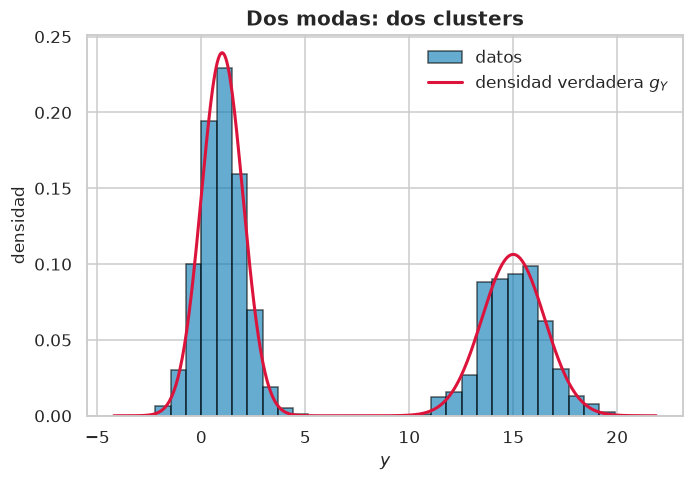

In [3]:
# El histograma de la celda 7, con la densidad verdadera encima para ver las dos modas.
fig, ax = plt.subplots()
ax.hist(samples, bins=30, density=True, alpha=0.6, color=colores[0], edgecolor="black", label="datos")
grilla = np.linspace(samples.min() - 2, samples.max() + 2, 500)
pi_real = n_2 / N
densidad_real = (1 - pi_real) * norm.pdf(grilla, mu_1, sigma_1) + pi_real * norm.pdf(grilla, mu_2, sigma_2)
ax.plot(grilla, densidad_real, color="crimson", lw=2, label="densidad verdadera $g_Y$")
ax.set_xlabel("$y$")
ax.set_ylabel("densidad")
ax.set_title("Dos modas: dos clusters")
ax.legend()
plt.show()

Las barras siguen la curva roja: dos picos, el de la izquierda más alto porque tiene 1200 de los 2000 datos (peso $0{,}6$). El de la derecha es más bajo y más ancho porque tiene menos datos y $\sigma_2 = 1{,}5$. La altura del pico depende del peso **y** del ancho: una gaussiana de peso $w$ y desvío $\sigma$ tiene altura máxima $w/(\sqrt{2\pi}\,\sigma)$.

#### 🖼️ La figura de la clase

La celda 8 es una imagen pegada en la notebook (no está en `src/figuras/`). Muestra un histograma con **dos modas que se pisan**: un pico alto alrededor de $y \approx 1$ y un segundo pico más bajo y ancho, aproximadamente entre 3,5 y 6. Entre los dos no hay un hueco vacío, solo un valle (cerca de $y \approx 3$). Se ve que no salió del código de la celda 7, cuyas montañas están en 1 y en 15.

Qué mirar: en la zona del valle **no podés decir a ojo de qué montaña viene cada dato**. Un $y = 3$ puede ser un dato alto de la primera o uno bajo de la segunda. Ese es el caso que motiva todo lo que sigue. Con montañas separadas, cortar en el medio alcanza. Con montañas pegadas, necesitás un modelo que reparta cada dato entre las dos con probabilidades. En la §7 vas a ver EM corriendo sobre un caso así.

### ⚠️ Confusión típica

Creer que la reducción de dimensionalidad y el clustering son lo mismo porque los dos hablan de "variables latentes". La de PCA es **continua** (una coordenada) y la de una mezcla es **discreta** (un grupo). Las dos responden preguntas distintas: "¿con cuántos números describo cada dato?" contra "¿de qué grupo es cada dato?".

Y ojo con el histograma: el número de modas que ves depende del ancho de las barras. Con barras muy anchas, dos montañas cercanas se funden en una; con barras muy finas, el ruido inventa montañas. Por eso se modela la densidad en vez de contar picos a ojo.

## 3. El modelo: una mezcla de dos gaussianas

📓 celdas 9–12 · 📕 ESL §8.5.1 · 📘 Bishop §9.2

### La idea en criollo

El modelo cuenta cómo nace cada dato, en dos pasos. Primero tirás una moneda cargada que sale "cara" con probabilidad $\pi$. Si sale ceca, sacás el dato de la gaussiana 1; si sale cara, de la gaussiana 2. Te quedás con el número y **tirás la moneda a la basura**. El resultado de la moneda es $\Delta_i$, y es justamente lo que no observás.

El resultado que sale de la clase: la densidad de los datos es el **promedio ponderado** de las dos densidades,

$$g_Y(y) = (1-\pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y).$$

Importa porque es una densidad con dos montañas armada con piezas que ya conocés. Hay cinco parámetros para estimar ($\mu_1, \sigma_1^2, \mu_2, \sigma_2^2, \pi$), y cada uno tiene un significado claro: dónde está cada montaña, qué tan ancha es y qué fracción de los datos tiene.

> **Dónde se rompe la analogía de la moneda.** La moneda sugiere que hay un "mecanismo real" con dos poblaciones. El modelo no lo necesita: a veces una mezcla de gaussianas se usa solo como forma flexible de aproximar una densidad rara, y las componentes no significan nada. Que el modelo ajuste bien no prueba que haya dos poblaciones.

### Formalizándolo

**Movidas:** M3 (condicionar en la latente $\Delta$ y promediar).

**El modelo (celda 9).**

$$Y_1 \sim \mathcal N(\mu_1, \sigma_1^2), \qquad Y_2 \sim \mathcal N(\mu_2, \sigma_2^2), \qquad Y = (1-\Delta)\,Y_1 + \Delta\,Y_2,$$

con $\Delta \sim \text{Bernoulli}(\pi)$ independiente de $Y_1$ y $Y_2$. Leé la última igualdad caso por caso. Si $\Delta = 0$, queda $Y = 1 \cdot Y_1 + 0 \cdot Y_2 = Y_1$. Si $\Delta = 1$, queda $Y = Y_2$. Es un "if" escrito como cuenta. $\pi$ es la fracción esperada de datos de la población 2 y $1-\pi$ la de la población 1.

**La conjunta de $(y_i, \Delta_i)$ (celdas 10–11).** Por la regla del producto, $p(y_i, \Delta_i) = P(\Delta_i)\,p(y_i \mid \Delta_i)$. Condicionado a $\Delta_i = 0$, $y_i$ es $\mathcal N(\mu_1, \sigma_1^2)$; condicionado a $\Delta_i = 1$, es $\mathcal N(\mu_2, \sigma_2^2)$. Escribiendo $\phi_\theta$ para la densidad normal con $\theta = (\mu, \sigma^2)$:

$$p(y_i, \Delta_i = 0) = (1-\pi)\,\phi_{\theta_1}(y_i), \qquad p(y_i, \Delta_i = 1) = \pi\,\phi_{\theta_2}(y_i).$$

**La marginal de $Y$ (celdas 11–12).** Para quedarte solo con $y$, sumás la conjunta sobre los valores posibles de $\Delta$ (marginalizar):

$$g_Y(y) = p(y, \Delta = 0) + p(y, \Delta = 1) = (1-\pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y).$$

La celda 12 llega a lo mismo por la **función de distribución**. Ese camino es M3: condicionás en el caso ($\Delta = 0$ o $\Delta = 1$), resolvés cada uno y promediás con sus probabilidades (probabilidad total).

$$P(Y \le y) = P(Y \le y \mid \Delta = 0)\,P(\Delta = 0) + P(Y \le y \mid \Delta = 1)\,P(\Delta = 1).$$

Condicionado a $\Delta = 0$, $Y = Y_1$. Además $Y_1$ es independiente de $\Delta$, así que $P(Y_1 \le y \mid \Delta = 0) = P(Y_1 \le y)$. Lo mismo con $Y_2$:

$$P(Y \le y) = (1-\pi)\,P(Y_1 \le y) + \pi\,P(Y_2 \le y) = (1-\pi)\int_{-\infty}^{y}\phi_{\theta_1}(t)\,dt + \pi\int_{-\infty}^{y}\phi_{\theta_2}(t)\,dt.$$

**El paso que la clase no escribe:** ¿para qué sirve la función de distribución si queríamos la densidad? La densidad es su derivada. Derivás respecto de $y$ y aplicás el teorema fundamental del cálculo a cada integral ($\frac{d}{dy}\int_{-\infty}^{y} f(t)\,dt = f(y)$):

$$g_Y(y) = \frac{d}{dy}P(Y \le y) = (1-\pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y).$$

Los dos caminos coinciden. El de la función de distribución tiene una ventaja: no supone que "sumar densidades conjuntas sobre $\Delta$" esté bien definido, porque trabaja con probabilidades de verdad.

**Chequeo de que es una densidad.** Es no negativa (suma de cosas no negativas con pesos en $[0, 1]$) e integra $(1-\pi) \cdot 1 + \pi \cdot 1 = 1$.

### ¿Por qué nos importa?

Porque ahora "encontrar los clusters" tiene una pregunta precisa: **¿cuánto valen los cinco parámetros?** (la pregunta de las celdas 11 y 13). Si los conocés, sabés dónde está cada montaña, y podés preguntar de cuál viene cada dato (§6).

Y porque la idea de **inventar una variable no observada que simplifica el modelo** es el centro de la clase. Con $\Delta$, la conjunta $p(y, \Delta)$ es un producto simple: una Bernoulli por una gaussiana. Sin $\Delta$, la marginal es una suma. Toda la dificultad de la §4 y toda la solución de la §5 vienen de esa diferencia.

### En código

Generamos datos **siguiendo el cuento** (moneda primero, gaussiana después) y chequeamos que la densidad $g_Y$ describe el histograma. Usamos un generador aparte (`rng`) para no tocar el estado del generador global, que la §7 necesita igual al de la clase.

fracción con Δ=1: 0.300 (π = 0.3)
max |dF/dy - g|: 3e-05


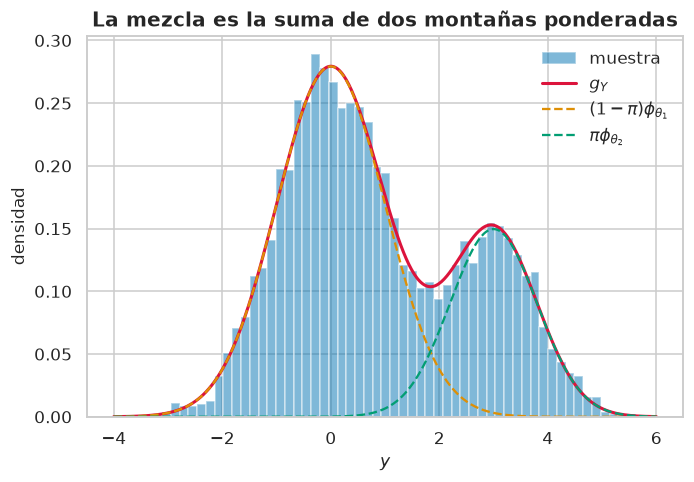

In [4]:
rng = np.random.default_rng(0)

def muestrear_mezcla(n, pi, th1, th2, rng):
    """El cuento de la celda 9: primero la moneda Δ, después la gaussiana que toque."""
    d = rng.random(n) < pi                       # Δ_i ~ Bernoulli(π)
    y = np.where(d, rng.normal(th2[0], th2[1], n), rng.normal(th1[0], th1[1], n))
    return y, d.astype(int)

y_sim, d_sim = muestrear_mezcla(5000, pi=0.3, th1=(0, 1), th2=(3, 0.8), rng=rng)
print(f"fracción con Δ=1: {d_sim.mean():.3f} (π = 0.3)")

g = lambda y: 0.7 * norm.pdf(y, 0, 1) + 0.3 * norm.pdf(y, 3, 0.8)
F = lambda y: 0.7 * norm.cdf(y, 0, 1) + 0.3 * norm.cdf(y, 3, 0.8)
yy = np.linspace(-4, 6, 400)
# La derivada numérica de la función de distribución tiene que dar la densidad (celda 12).
print("max |dF/dy - g|:", np.max(np.abs(np.gradient(F(yy), yy) - g(yy))).round(5))

fig, ax = plt.subplots()
ax.hist(y_sim, bins=60, density=True, alpha=0.5, color=colores[0], label="muestra")
ax.plot(yy, g(yy), color="crimson", lw=2, label="$g_Y$")
ax.plot(yy, 0.7 * norm.pdf(yy, 0, 1), "--", color=colores[1], label=r"$(1-\pi)\phi_{\theta_1}$")
ax.plot(yy, 0.3 * norm.pdf(yy, 3, 0.8), "--", color=colores[2], label=r"$\pi\phi_{\theta_2}$")
ax.set_xlabel("$y$"); ax.set_ylabel("densidad"); ax.set_title("La mezcla es la suma de dos montañas ponderadas")
ax.legend(); plt.show()

La fracción simulada de $\Delta = 1$ da cerca de $0{,}3$ y la derivada numérica de la función de distribución coincide con $g_Y$ hasta el error de la aproximación: lo de la celda 12, en números. En el gráfico, la curva roja es **la suma** de las dos punteadas. En el valle (cerca de $y \approx 2$) las dos punteadas aportan: ahí un dato puede venir de cualquiera de las dos.

### ⚠️ Confusión típica

Confundir la **mezcla** de densidades con la **suma** de variables aleatorias. $Y = (1-\Delta)Y_1 + \Delta Y_2$ **no** es $Y_1 + Y_2$: elige una de las dos. Si sumaras $Y_1 + Y_2$ tendrías **una sola** gaussiana con media $\mu_1 + \mu_2$, sin dos modas. Lo que se suma con pesos son las **densidades**, no las variables.

Segunda trampa: escribir $g_Y(y) = \phi_{\theta_1}(y) + \phi_{\theta_2}(y)$ sin los pesos. Eso integra 2, no 1: no es una densidad.

## 4. Máxima verosimilitud: por qué se traba (y qué te dice la derivada)

📓 celda 13 · 📕 ESL §8.5.1 · 📘 Bishop §9.2.1

### La idea en criollo

La pregunta de la celda 13 es cómo estimar los cinco parámetros, y la respuesta es la de siempre: máxima verosimilitud. Escribís la log-verosimilitud y la maximizás.

El problema es que acá el log **no rompe nada**. En la regresión y en la logística el log convertía un producto en una suma de términos simples. Acá cada término es el log **de una suma** de dos densidades, y $\log(a + b)$ no se separa. Si derivás e igualás a cero, no podés despejar.

El resultado que tenés que llevarte, y que la clase no muestra: si derivás igual, la condición de óptimo para $\mu_2$ queda

$$\mu_2 = \frac{\sum_i \gamma_i\, y_i}{\sum_i \gamma_i},$$

un **promedio ponderado** de los datos con pesos $\gamma_i$, que son la probabilidad de que $y_i$ venga de la componente 2. Pero los pesos **dependen de $\mu_2$**. Es una ecuación de punto fijo: $\mu_2$ aparece de los dos lados. No hay forma cerrada, pero hay una receta obvia: adiviná, calculá los pesos, recalculá $\mu_2$, repetí. Eso es EM.

### Formalizándolo

**Movidas:** M10 (log de la verosimilitud), M1 (derivar e igualar a 0).

**La log-verosimilitud (celda 13).** Los $y_i$ son independientes, así que la verosimilitud es el producto de las densidades $g_Y(y_i)$. Tomamos log (M10) y el producto pasa a suma:

$$\ell(\theta; \mathbf Z) = \log\prod_{i=1}^N g_Y(y_i) = \sum_{i=1}^N \log\big[(1-\pi)\,\phi_{\theta_1}(y_i) + \pi\,\phi_{\theta_2}(y_i)\big].$$

Hasta acá, M10 hizo su trabajo: un producto de $N$ factores pasó a una suma de $N$ términos. Pero cada término es el log de una suma, y ahí el log no tiene nada que separar.

**Derivamos igual (M1).** Lo hacemos respecto de $\mu_2$. Abreviamos $g_i = (1-\pi)\phi_{\theta_1}(y_i) + \pi\phi_{\theta_2}(y_i)$.

*Paso 1.* La derivada del log es la derivada de adentro sobre lo de adentro. El término con $\phi_{\theta_1}$ no depende de $\mu_2$:

$$\frac{\partial \ell}{\partial \mu_2} = \sum_{i=1}^N \frac{\pi\,\frac{\partial}{\partial\mu_2}\phi_{\theta_2}(y_i)}{g_i}.$$

*Paso 2.* La derivada de la gaussiana respecto de su media. Como $\phi_{\theta_2}(y) = \frac{1}{\sqrt{2\pi\sigma_2^2}}\exp\!\big(-\frac{(y-\mu_2)^2}{2\sigma_2^2}\big)$, por la regla de la cadena:

$$\frac{\partial}{\partial\mu_2}\phi_{\theta_2}(y) = \phi_{\theta_2}(y)\cdot\frac{y - \mu_2}{\sigma_2^2}.$$

(La derivada del exponente $-\frac{(y-\mu_2)^2}{2\sigma_2^2}$ respecto de $\mu_2$ es $-\frac{2(y-\mu_2)(-1)}{2\sigma_2^2} = \frac{y-\mu_2}{\sigma_2^2}$.)

*Paso 3.* Reemplazamos y reagrupamos:

$$\frac{\partial \ell}{\partial \mu_2} = \sum_{i=1}^N \underbrace{\frac{\pi\,\phi_{\theta_2}(y_i)}{g_i}}_{=:\ \gamma_i}\cdot\frac{y_i - \mu_2}{\sigma_2^2}.$$

El cociente marcado es la **responsabilidad** $\gamma_i$ de la celda 18 (en la §6 vas a ver que es $P(\Delta_i = 1 \mid y_i)$). Apareció sola, de derivar.

*Paso 4.* Igualamos a 0. $\sigma_2^2 > 0$ sale como factor común y se va:

$$\sum_i \gamma_i\,(y_i - \mu_2) = 0 \quad\Longrightarrow\quad \mu_2 = \frac{\sum_i \gamma_i\, y_i}{\sum_i \gamma_i}.$$

Por simetría, para $\mu_1$ la cuenta da lo mismo con $1 - \gamma_i$ en lugar de $\gamma_i$: $\frac{(1-\pi)\phi_{\theta_1}(y_i)}{g_i} = 1 - \gamma_i$.

**Por qué no es una forma cerrada.** $\gamma_i$ tiene $\mu_2$ adentro (en $\phi_{\theta_2}$ y en $g_i$). La ecuación es $\mu_2 = h(\mu_2)$. No se despeja, pero se puede **iterar**: con un $\mu_2$ viejo calculás los $\gamma_i$ y con ellos un $\mu_2$ nuevo. La §7 muestra que esa iteración, hecha para todos los parámetros a la vez, es exactamente EM.

**Lo mismo con $\sigma_2^2$ y $\pi$** (para que tengas las tres; mismos pasos):

- $\frac{\partial}{\partial\sigma_2^2}\phi_{\theta_2}(y) = \phi_{\theta_2}(y)\Big[-\frac{1}{2\sigma_2^2} + \frac{(y-\mu_2)^2}{2\sigma_2^4}\Big]$, así que $\frac{\partial\ell}{\partial\sigma_2^2} = \sum_i \gamma_i\Big[\frac{(y_i-\mu_2)^2 - \sigma_2^2}{2\sigma_2^4}\Big] = 0 \Rightarrow \sigma_2^2 = \frac{\sum_i\gamma_i(y_i-\mu_2)^2}{\sum_i\gamma_i}$.
- $\frac{\partial\ell}{\partial\pi} = \sum_i \frac{\phi_{\theta_2}(y_i) - \phi_{\theta_1}(y_i)}{g_i} = \sum_i\Big[\frac{\gamma_i}{\pi} - \frac{1-\gamma_i}{1-\pi}\Big]$, usando $\frac{\phi_{\theta_2}}{g_i} = \frac{\gamma_i}{\pi}$ y $\frac{\phi_{\theta_1}}{g_i} = \frac{1-\gamma_i}{1-\pi}$. Igualando a 0 y multiplicando por $\pi(1-\pi)$: $(1-\pi)\sum_i\gamma_i = \pi\big(N - \sum_i\gamma_i\big)$, o sea $\pi = \frac{1}{N}\sum_i\gamma_i$.

Son, letra por letra, las fórmulas del M-step de la celda 20.

**Un problema que la clase no menciona: la verosimilitud no tiene máximo.** Poné $\mu_1 = y_1$ (exactamente un dato) y hacé $\sigma_1 \to 0$. El término $i = 1$ tiene $\phi_{\theta_1}(y_1) = \frac{1}{\sqrt{2\pi}\,\sigma_1} \to \infty$, y su log también. Los demás términos no se van a $-\infty$, porque la componente 2 sigue dándoles densidad positiva. Entonces $\ell \to +\infty$. El "máximo global" es una gaussiana degenerada sentada sobre un punto, que no sirve para nada. ESL §8.5.1 y Bishop §9.2.1 lo advierten. Lo que se busca en la práctica es un **máximo local bueno**, y EM, arrancando de un punto razonable, suele encontrarlo.

### ¿Por qué nos importa?

Porque te muestra **de dónde sale EM** sin ningún truco. La clase llega al M-step por la verosimilitud completa (§5) y la esperanza (§7): es el camino de los libros. El de esta sección es más corto y es el que conviene **reproducir en frío**: derivás la log-verosimilitud de la mezcla, aparece $\gamma_i$ y ves que la condición de óptimo es "promedio ponderado por $\gamma_i$".

Y porque te avisa qué esperar: EM no puede encontrar "el" máximo porque no existe. Si en una corrida una $\hat\sigma_k$ se va a cero, no es un bug: es la verosimilitud degenerándose.

### En código

In [5]:
def loglik(y, pi, mu1, s1, mu2, s2):
    """ℓ de la celda 13: suma de logs de la densidad de la mezcla."""
    return np.sum(np.log((1 - pi) * norm.pdf(y, mu1, s1) + pi * norm.pdf(y, mu2, s2)))

print(f"ℓ en los parámetros verdaderos: {loglik(samples, n_2/N, mu_1, sigma_1, mu_2, sigma_2):.1f}")

# Degeneración: componente 1 sentada sobre un dato, componente 2 = una gaussiana ancha que cubre todo.
m, s = samples.mean(), samples.std()
for s1 in [1e-2, 1e-10, 1e-100, 1e-300]:
    print(f"σ1 = {s1:.0e}  ->  ℓ = {loglik(samples, 0.5, samples[0], s1, m, s):.1f}")
# Para σ1 chico, ℓ = A − log σ1 (solo el término de y_1 depende de σ1). ¿Con qué σ1 le gana a la verdad?
A = loglik(samples, 0.5, samples[0], 1e-300, m, s) + np.log(1e-300)
ell_verdad = loglik(samples, n_2/N, mu_1, sigma_1, mu_2, sigma_2)
print(f"ℓ supera a la de los parámetros verdaderos con σ1 < 10^{(A - ell_verdad) / np.log(10):.0f}")

# La condición de óptimo es un punto fijo: en los parámetros verdaderos, el promedio ponderado ≈ μ2.
p1, p2 = norm.pdf(samples, mu_1, sigma_1), norm.pdf(samples, mu_2, sigma_2)
gam = (n_2/N) * p2 / ((1 - n_2/N) * p1 + (n_2/N) * p2)
print(f"Σγy/Σγ = {np.sum(gam * samples) / np.sum(gam):.3f}  (μ2 verdadero = {mu_2})")

ℓ en los parámetros verdaderos: -4561.8
σ1 = 1e-02  ->  ℓ = -7965.5
σ1 = 1e-10  ->  ℓ = -8085.8
σ1 = 1e-100  ->  ℓ = -7878.5
σ1 = 1e-300  ->  ℓ = -7418.0
ℓ supera a la de los parámetros verdaderos con σ1 < 10^-1540
Σγy/Σγ = 15.010  (μ2 verdadero = 15)


/home/gerar/facultad/aprendizaje-automatico-2c2026/.venv/lib/python3.14/site-packages/scipy/stats/_continuous_distns.py:363: RuntimeWarning: overflow encountered in square
  return np.exp(-x**2/2.0) / _norm_pdf_C


Tres cosas en la salida:

1. En los parámetros verdaderos $\ell$ es un número finito y negativo (densidades menores que 1 en promedio, logs negativos).
2. Con $\mu_1$ sobre un dato y $\sigma_1$ cada vez más chico, $\ell$ termina **creciendo sin techo**. Entre $10^{-2}$ y $10^{-10}$ todavía baja: con $\sigma_1 = 10^{-2}$ la componente angosta les da algo de densidad a los datos vecinos de $y_1$, y al achicarla se la quita. Una vez que solo cubre a $y_1$, cada vez que dividís $\sigma_1$ por 10, $\ell$ sube $\log 10 \approx 2{,}3$ (el término $-\log\sigma_1$ del dato $y_1$; los demás los cubre la componente ancha y no cambian). Crece lento: para ganarle a los parámetros verdaderos hace falta un $\sigma_1$ absurdamente chico, el de la última línea. Pero le gana, y sigue subiendo: el supremo es $+\infty$. Es la degeneración, en números.
3. Con los $\gamma_i$ calculados en los parámetros verdaderos, el promedio ponderado de los datos da muy cerca de $15$. Los parámetros verdaderos casi cumplen la ecuación de punto fijo; no exactamente, porque el óptimo de $\ell$ es el estimador $\hat\mu_2$, que con una muestra finita no coincide con el valor verdadero.

### ❓ La pregunta que quedó abierta

La celda 13 dice que *"es difícil maximizar esta función directamente, ya que hay términos de suma dentro del logaritmo"*. ¿Difícil o imposible? **Sin forma cerrada**, que no es lo mismo que imposible. Podrías maximizar $\ell$ con descenso por gradiente o con Newton (M9), cuidando que $\sigma_k^2 > 0$ y $0 \le \pi \le 1$. EM es preferible porque cada paso tiene forma cerrada, respeta solo esas restricciones (las varianzas que produce son promedios de cuadrados y $\hat\pi$ es un promedio de números en $[0, 1]$) y no necesita tasa de aprendizaje.

### ⚠️ Confusión típica

Creer que M10 "siempre separa". El log convierte **productos** en sumas, nada más. Si la densidad de cada dato ya es una suma, el log no la parte: $\log(a + b) \neq \log a + \log b$. Ese error de álgebra, aplicado a $\ell$, te da un problema fácil y equivocado.

Y no confundas los dos $\pi$: en $\frac{1}{\sqrt{2\pi\sigma^2}}$ es el número; en $(1-\pi)\phi_{\theta_1} + \pi\phi_{\theta_2}$ es el peso de la mezcla.

## 5. Si conociéramos las $\Delta_i$: la verosimilitud completa

📓 celdas 14–16 · 📕 ESL §8.5.1 · 📘 Bishop §9.3.1

### La idea en criollo

Imaginá por un momento que alguien te dice de qué gaussiana salió cada dato. Entonces el problema se parte en tres problemas que ya sabés resolver. Estimás la gaussiana 1 con los datos del grupo 1: promedio y varianza de ese grupo. Lo mismo con el grupo 2. Y estimás $\pi$ con la fracción de datos del grupo 2.

El resultado: con las $\Delta_i$ a la vista, la log-verosimilitud **completa** se separa en pedazos independientes, uno por parámetro, y cada estimador es un promedio por grupo. Importa porque ese "promedio por grupo" es el molde del M-step. Lo único que va a cambiar en EM es que las $\Delta_i$, que valen 0 o 1, se reemplazan por probabilidades $\gamma_i$ entre 0 y 1.

> **Analogía y dónde se rompe.** Es como calcular la altura promedio de hombres y mujeres con una planilla que tiene la columna "sexo": separás y promediás. Se rompe en lo obvio y central de esta clase: **esa columna no está**. La verosimilitud completa no se puede evaluar con datos reales. Es una herramienta para pensar, no un estimador que puedas usar.

### Formalizándolo

**Movidas:** M10 (el log convierte producto en suma y los exponentes en factores), M1 (derivar e igualar a 0).

**Una fórmula para los dos casos (celda 15).** Teníamos $p(y_i, 0) = (1-\pi)\phi_{\theta_1}(y_i)$ y $p(y_i, 1) = \pi\phi_{\theta_2}(y_i)$. Las dos se escriben juntas usando $\Delta_i$ como **exponente selector**:

$$p(y_i, \Delta_i) = \big[(1-\pi)\,\phi_{\theta_1}(y_i)\big]^{1-\Delta_i}\,\big[\pi\,\phi_{\theta_2}(y_i)\big]^{\Delta_i}.$$

Chequeo: con $\Delta_i = 0$ el segundo factor queda a la cero, vale 1, y queda el primero. Con $\Delta_i = 1$ pasa al revés.

**La verosimilitud completa.** Si los pares $(y_i, \Delta_i)$ son independientes, es el producto:

$$L_0(\theta; \mathbf Z, \boldsymbol\Delta) = \prod_{i=1}^N \big[(1-\pi)\,\phi_{\theta_1}(y_i)\big]^{1-\Delta_i}\,\big[\pi\,\phi_{\theta_2}(y_i)\big]^{\Delta_i}.$$

**Tomamos log (M10).** El producto pasa a suma y cada exponente baja como factor ($\log a^b = b\log a$):

$$\ell_0(\theta; \mathbf Z, \boldsymbol\Delta) = \sum_{i=1}^N\Big[(1-\Delta_i)\log\big[(1-\pi)\phi_{\theta_1}(y_i)\big] + \Delta_i\log\big[\pi\phi_{\theta_2}(y_i)\big]\Big].$$

Ahora el log **sí** separa, porque adentro hay un **producto** de dos factores ($\log(ab) = \log a + \log b$). Reagrupamos (celda 14):

$$\ell_0 = \underbrace{\sum_{i}(1-\Delta_i)\log\phi_{\theta_1}(y_i)}_{\text{solo } \mu_1, \sigma_1^2} + \underbrace{\sum_{i}\Delta_i\log\phi_{\theta_2}(y_i)}_{\text{solo } \mu_2, \sigma_2^2} + \underbrace{\sum_{i}\big[(1-\Delta_i)\log(1-\pi) + \Delta_i\log\pi\big]}_{\text{solo } \pi}.$$

Comparalo con la §4. Allá el log de una suma ataba todos los parámetros en cada término. Acá hay tres sumas, cada una con sus propios parámetros. Maximizar $\ell_0$ es maximizar cada sumando por separado.

**Los estimadores (celda 16, con el paso que falta).** La clase los enuncia; los derivamos. Escribimos $N_1 = \sum_i(1-\Delta_i)$ (cuántos datos del grupo 1) y $N_2 = \sum_i\Delta_i$ (cuántos del grupo 2). Y $\log\phi_{\theta_1}(y) = -\tfrac12\log(2\pi\sigma_1^2) - \frac{(y-\mu_1)^2}{2\sigma_1^2}$.

*La media (M1).* Derivamos el primer sumando respecto de $\mu_1$. El término $-\frac12\log(2\pi\sigma_1^2)$ no depende de $\mu_1$:

$$\frac{\partial\ell_0}{\partial\mu_1} = \sum_i(1-\Delta_i)\,\frac{y_i - \mu_1}{\sigma_1^2} = 0 \quad\Longrightarrow\quad \hat\mu_1 = \frac{\sum_i(1-\Delta_i)\,y_i}{\sum_i(1-\Delta_i)} = \frac{1}{N_1}\sum_{i:\,\Delta_i = 0} y_i.$$

Es el promedio de los datos del grupo 1. El factor $(1-\Delta_i)$ apaga los del grupo 2.

*La varianza (M1).* Derivamos respecto de $\sigma_1^2$ (tratándola como **una** variable, $v = \sigma_1^2$):

$$\frac{\partial\ell_0}{\partial\sigma_1^2} = \sum_i(1-\Delta_i)\Big[-\frac{1}{2\sigma_1^2} + \frac{(y_i-\mu_1)^2}{2\sigma_1^4}\Big] = 0.$$

Multiplicamos por $2\sigma_1^4$: $\sum_i(1-\Delta_i)\big[(y_i - \mu_1)^2 - \sigma_1^2\big] = 0$, y con $\mu_1 = \hat\mu_1$:

$$\hat\sigma_1^2 = \frac{\sum_i(1-\Delta_i)(y_i - \hat\mu_1)^2}{\sum_i(1-\Delta_i)}.$$

Es la varianza empírica del grupo 1, **con divisor $N_1$**, no $N_1 - 1$: el de máxima verosimilitud, sesgado (como en la clase 3).

*La proporción (M1).* El tercer sumando es $N_1\log(1-\pi) + N_2\log\pi$. Derivamos:

$$-\frac{N_1}{1-\pi} + \frac{N_2}{\pi} = 0 \quad\Longrightarrow\quad N_2(1-\pi) = N_1\pi \quad\Longrightarrow\quad \hat\pi = \frac{N_2}{N_1 + N_2} = \frac{1}{N}\sum_i\Delta_i.$$

*¿Son máximos?* Las segundas derivadas son negativas: $-N_1/\sigma_1^2$ para la media y $-\frac{N_1}{(1-\pi)^2} - \frac{N_2}{\pi^2}$ para $\pi$. Para la varianza, en el punto crítico la segunda derivada vale $-\frac{N_1}{2\hat\sigma_1^4} < 0$. Con un único punto crítico en cada problema, es el máximo.

Los de la componente 2 son iguales con $\Delta_i$ en lugar de $1 - \Delta_i$.

### ¿Por qué nos importa?

Porque te deja el **molde**. Fijate en la forma: "suma ponderada de los $y_i$ sobre suma de los pesos", con pesos $(1-\Delta_i)$ o $\Delta_i$. Ahora poné $1 - \gamma_i$ y $\gamma_i$ en esos lugares y tenés las fórmulas de la celda 20. El M-step **no es nada nuevo**: son estos estimadores con pesos fraccionarios.

Y la frase final de la celda 16, *"Pero no conocemos las $\Delta_i$…"*, es la que arma el resto de la clase. Te quedan dos caminos: adivinar las $\Delta_i$ (asignación dura) o estimar **cuán probable** es cada una (asignación suave). EM toma el segundo.

### En código

En la simulación **sí** conocemos las $\Delta_i$ (las guardamos en `delta`). Calculamos los estimadores de la celda 16 con ellas, a mano.

In [6]:
# Estimadores con Δ conocidas (celda 16). Solo posible porque simulamos: en la práctica no hay `delta`.
w1, w2 = 1 - delta, delta
mu1_hat = np.sum(w1 * samples) / np.sum(w1)
mu2_hat = np.sum(w2 * samples) / np.sum(w2)
s1_hat = np.sqrt(np.sum(w1 * (samples - mu1_hat) ** 2) / np.sum(w1))   # divisor N1: MV
s2_hat = np.sqrt(np.sum(w2 * (samples - mu2_hat) ** 2) / np.sum(w2))
pi_hat = np.mean(delta)

completa = pd.DataFrame({
    "verdadero": [mu_1, sigma_1, mu_2, sigma_2, n_2 / N],
    "con Δ conocidas": [mu1_hat, s1_hat, mu2_hat, s2_hat, pi_hat],
}, index=["μ1", "σ1", "μ2", "σ2", "π"])
print(completa.round(3))
# Chequeo: es lo mismo que separar en grupos y usar np.mean / np.std (ddof=0).
print(np.isclose(mu1_hat, samples[delta == 0].mean()), np.isclose(s2_hat, samples[delta == 1].std()))

    verdadero  con Δ conocidas
μ1        1.0            0.989
σ1        1.0            1.028
μ2       15.0           15.010
σ2        1.5            1.535
π         0.4            0.400
True True


Con las etiquetas a la vista los estimadores caen muy cerca de los valores verdaderos, y coinciden exactamente con "separar por grupo y usar `mean` / `std`" (los dos `True`). La tabla es la **meta**: en la §7, EM tiene que llegar a algo parecido **sin** mirar `delta`.

### ❓ La pregunta que quedó abierta

La celda 16 dice que $\hat\sigma_1^2$ es la *"varianza empírica"* pero no da la fórmula. Es la de arriba, con divisor $N_1$. ¿Por qué no $N_1 - 1$? Porque máxima verosimilitud no busca insesgadez. Con $N_1 = 1200$ la diferencia es de una parte en 1200 y no importa. En EM sí puede importar: si una componente se queda con muy pocos datos, el divisor chico hace que $\hat\sigma^2$ se achique, y eso es el principio de la degeneración de la §4.

### ⚠️ Confusión típica

Creer que $\ell_0$ es "la" verosimilitud del problema. No lo es: depende de $\boldsymbol\Delta$, que no observás. La verosimilitud de los datos que tenés es la $\ell$ de la §4. $\ell_0$ es la de un problema imaginario más fácil, y EM la usa como escalón.

Segunda: olvidarse de que en $\hat\sigma_1^2$ va $\hat\mu_1$ (ya estimado), no el $\mu_1$ verdadero ni el de la iteración anterior. En el código de la celda 21 fijate el orden: primero `mu_1_i`, después `sigma_1_i` usando `mu_1_i`.

## 6. El E-step: responsabilidades como asignación suave

📓 celdas 17–18 · 📕 ESL §8.5.1 · 📘 Bishop §9.2

### La idea en criollo

No conocés $\Delta_i$, pero si conocieras los parámetros podrías **apostar** con fundamento. Un dato en $y = 14$ casi seguro salió de la gaussiana centrada en 15; uno en $y = 8$, en el medio, es dudoso. La **responsabilidad** $\gamma_i$ es esa apuesta hecha número: la probabilidad de que $y_i$ venga de la componente 2, **dado lo que viste**.

El resultado: $\gamma_i$ sale de la regla de Bayes, igual que el posterior de clase en LDA (clase 6). Es el peso de la componente 2 en ese punto, dividido el peso total:

$$\gamma_i = \frac{\pi\,\phi_{\theta_2}(y_i)}{(1-\pi)\,\phi_{\theta_1}(y_i) + \pi\,\phi_{\theta_2}(y_i)}.$$

Además, $\gamma_i = E[\Delta_i \mid \text{datos}]$: es la mejor predicción de $\Delta_i$ con pérdida cuadrática. Por eso es lo que va en el lugar de $\Delta_i$ cuando no la tenés.

> **Analogía y dónde se rompe.** Es como un médico que da "70 % de que sea gripe" en vez de un diagnóstico seco. La analogía se rompe en que el médico tiene años de casos etiquetados; acá las probabilidades salen de parámetros que **también** estás estimando. Si los parámetros están mal, las responsabilidades salen seguras y equivocadas.

### Formalizándolo

**Movidas:** ninguna del catálogo. Es la regla de Bayes (resultado de la clase; ver la nota al final de la notebook sobre una posible movida nueva).

**$\gamma_i$ es una esperanza y una probabilidad a la vez (celda 18).** $\Delta_i$ vale 0 o 1. Para una variable así, la esperanza es la probabilidad de que valga 1:

$$E[\Delta_i \mid \theta, \mathbf Z] = 0\cdot P(\Delta_i = 0 \mid \theta, \mathbf Z) + 1\cdot P(\Delta_i = 1 \mid \theta, \mathbf Z) = P(\Delta_i = 1 \mid \theta, \mathbf Z).$$

**De todos los datos a uno solo.** La condición dice "dado $\mathbf Z$", todos los datos. Pero los pares $(y_j, \Delta_j)$ son independientes entre sí, así que los $y_j$ con $j \neq i$ no dicen nada sobre $\Delta_i$: $P(\Delta_i = 1 \mid \theta, \mathbf Z) = P(\Delta_i = 1 \mid \theta, y_i)$.

**Bayes.** Probabilidad condicional = conjunta sobre marginal. La conjunta la escribimos en la §3 y la marginal es $g_Y$:

$$\gamma_i = P(\Delta_i = 1 \mid y_i) = \frac{p(y_i, \Delta_i = 1)}{g_Y(y_i)} = \frac{\pi\,\phi_{\theta_2}(y_i)}{(1-\pi)\,\phi_{\theta_1}(y_i) + \pi\,\phi_{\theta_2}(y_i)}.$$

Numerador: prior ($\pi$) por verosimilitud ($\phi_{\theta_2}(y_i)$). Denominador: la suma de lo mismo para las dos componentes, para que las dos probabilidades sumen 1. Y $1 - \gamma_i = P(\Delta_i = 0 \mid y_i)$ es la responsabilidad de la componente 1.

**Por qué "suave" (celdas 17–18).** La clase dice que $\gamma_i$ es *"un estimador de $\Delta_i$, salvo que $\gamma_i \in [0,1]$"*. $\Delta_i$ vale 0 o 1 (asignación **dura**). $\gamma_i$ puede valer $0{,}5$ (asignación **suave**): el dato se reparte entre las dos componentes. Un dato con $\gamma_i = 0{,}3$ cuenta como 0,3 de dato en la componente 2 y 0,7 en la componente 1.

**¿Por qué $E[\Delta_i]$ y no otra cosa?** Por M2: $E[\Delta_i \mid y_i]$ es el $c$ que minimiza $E[(\Delta_i - c)^2 \mid y_i]$, la mejor predicción con pérdida cuadrática. La razón de fondo de que sea **la esperanza** (y no la moda, por ejemplo) la vas a ver en la §7: $\ell_0$ es lineal en $\Delta_i$, y la esperanza de algo lineal se calcula enchufando la esperanza.

**¿Dónde vale $\gamma = 1/2$?** Donde $\pi\phi_{\theta_2}(y) = (1-\pi)\phi_{\theta_1}(y)$: donde las dos montañas **ponderadas** tienen la misma altura. Esa es la frontera entre clusters. Con $\pi = 1/2$ y $\sigma_1 = \sigma_2$ queda en el punto medio $(\mu_1 + \mu_2)/2$. Si una componente pesa más ($\pi$ distinto de $1/2$), la frontera se corre hacia la otra; si tienen distinta varianza, la más ancha vuelve a ganar lejos de las dos medias y puede haber **dos** fronteras.

### ¿Por qué nos importa?

Porque es exactamente la fórmula del posterior en LDA y QDA de la clase 6: $P(G = k \mid x) = \frac{\pi_k f_k(x)}{\sum_l \pi_l f_l(x)}$. La diferencia: en LDA las etiquetas estaban en los datos de entrenamiento y estimabas $\pi_k$, $\mu_k$, $\Sigma$ con promedios por clase. Acá no hay etiquetas. **EM es QDA sin etiquetas**: usa el posterior para inventar etiquetas suaves y con ellas estima los parámetros, como haría QDA.

Y porque deja la cuenta trabada en la frase de la celda 18: *"Pero no conocemos los parámetros $\theta$…"*. Para $\gamma_i$ necesitás $\theta$; para $\theta$ necesitás las $\Delta_i$ (o los $\gamma_i$). Es el huevo y la gallina. La salida es arrancar con un $\theta$ cualquiera y alternar: la §7.

### En código

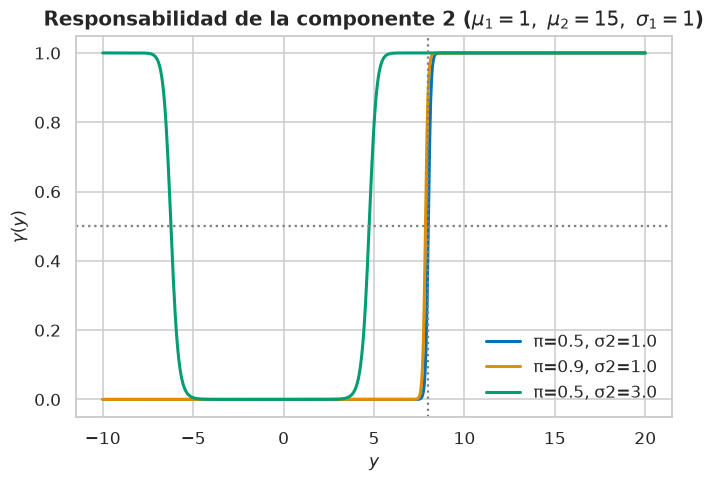

γ en los datos con los parámetros verdaderos: min, max = 0.0 1.0
datos con 0.01 < γ < 0.99: 0


In [7]:
def responsabilidad(y, pi, mu1, s1, mu2, s2):
    """γ(y) = P(Δ=1 | y), celda 18."""
    a, b = (1 - pi) * norm.pdf(y, mu1, s1), pi * norm.pdf(y, mu2, s2)
    return b / (a + b)

yy = np.linspace(-10, 20, 600)
fig, ax = plt.subplots()
for pi_, s2_, c in [(0.5, 1.0, colores[0]), (0.9, 1.0, colores[1]), (0.5, 3.0, colores[2])]:
    ax.plot(yy, responsabilidad(yy, pi_, 1, 1, 15, s2_), color=c, lw=2, label=f"π={pi_}, σ2={s2_}")
ax.axhline(0.5, ls=":", color="gray")
ax.axvline(8, ls=":", color="gray")
ax.set_xlabel("$y$"); ax.set_ylabel(r"$\gamma(y)$")
ax.set_title(r"Responsabilidad de la componente 2 ($\mu_1=1,\ \mu_2=15,\ \sigma_1=1$)")
ax.legend(); plt.show()

print("γ en los datos con los parámetros verdaderos: min, max =", gam.min().round(4), gam.max().round(4))
print("datos con 0.01 < γ < 0.99:", np.sum((gam > 0.01) & (gam < 0.99)))

Qué mirar:

- **Azul** ($\pi = 0{,}5$, varianzas iguales): una escalera que pasa por $1/2$ justo en $y = 8$, el punto medio entre 1 y 15.
- **Naranja** ($\pi = 0{,}9$): la componente 2 pesa más y "se queda" con datos más cerca de la componente 1. La frontera se corre a la izquierda de 8.
- **Verde** ($\sigma_2 = 3$): la componente 2, más ancha, gana en el medio **y también muy a la izquierda**: lejos de las dos medias, la gaussiana más ancha tiene colas más pesadas. La curva vuelve a subir a la izquierda de la componente 1, con una segunda frontera. Por eso dije que puede haber dos.

Los prints: con las montañas de la clase tan separadas, casi todos los $\gamma_i$ son prácticamente 0 o 1. Ningún dato queda en zona dudosa (entre 0,01 y 0,99). Si las montañas se pisaran, como en la figura de la celda 8, habría muchos.

### ⚠️ Confusión típica

Confundir $\gamma_i$ con $\pi$. $\pi$ es la proporción **global** de la componente 2, la misma para todos los datos. $\gamma_i$ es la probabilidad para **ese** dato, después de ver dónde cayó. El promedio de los $\gamma_i$ estima $\pi$ (la fórmula del M-step), pero cada uno puede estar lejísimos de $\pi$.

Otra: escribir $\gamma_i = \frac{\phi_{\theta_2}(y_i)}{\phi_{\theta_1}(y_i) + \phi_{\theta_2}(y_i)}$ olvidando los pesos. Eso solo vale con $\pi = 1/2$.

## 7. El algoritmo EM: alternar hasta converger

📓 celdas 19–25 y 29 · 📕 ESL §8.5.1–8.5.2 · 📘 Bishop §9.2.2 y §9.4

### La idea en criollo

Tenés un problema circular: para las responsabilidades necesitás los parámetros, y para los parámetros, las responsabilidades. EM lo rompe arrancando de un lado cualquiera y alternando:

1. **Inicializar** los cinco parámetros con algo razonable.
2. **E-step:** con los parámetros actuales, calcular cada $\gamma_i$ (Bayes, §6).
3. **M-step:** con los $\gamma_i$ fijos, recalcular medias, varianzas y $\pi$ como promedios **ponderados** (§5 con $\gamma_i$ en lugar de $\Delta_i$).
4. Repetir 2 y 3 hasta que nada cambie.

El resultado: cada vuelta **sube (o deja igual) la log-verosimilitud** de los datos. Y converge a un punto donde las fórmulas del M-step se cumplen con los $\gamma_i$ de esos mismos parámetros: el punto fijo de la §4. Ese punto es un **máximo local**. Por eso se inicializa con cuidado, y en la práctica se corre varias veces desde distintos arranques y se queda con la de mayor $\ell$.

> **Analogía y dónde se rompe.** Es como dos personas que acomodan una mesa. Una mueve las sillas según dónde está la mesa; la otra corre la mesa según dónde quedaron las sillas. Repiten hasta que nadie mueve nada. Se rompe en una garantía que la analogía no tiene: en EM cada movida **nunca empeora** el objetivo. Y en que pueden quedar trabados en un acomodamiento que no es el mejor.

### Formalizándolo

**Movidas:** M1 (el M-step maximiza con forma cerrada), M10 (verosimilitud completa). Resultado propio: la linealidad de $\ell_0$ en $\Delta_i$.

**El algoritmo (celdas 19–20, ESL §8.5.1).**

1. Inicializar $\hat\mu_1, \hat\sigma_1^2, \hat\mu_2, \hat\sigma_2^2, \hat\pi$.
2. **E-step.** $\hat\gamma_i = \dfrac{\hat\pi\,\phi_{\hat\theta_2}(y_i)}{(1-\hat\pi)\,\phi_{\hat\theta_1}(y_i) + \hat\pi\,\phi_{\hat\theta_2}(y_i)}$, para $i = 1, \dots, N$.
3. **M-step.**
$$\hat\mu_1 = \frac{\sum_i(1-\hat\gamma_i)\,y_i}{\sum_i(1-\hat\gamma_i)}, \qquad \hat\sigma_1^2 = \frac{\sum_i(1-\hat\gamma_i)(y_i - \hat\mu_1)^2}{\sum_i(1-\hat\gamma_i)},$$
$$\hat\mu_2 = \frac{\sum_i\hat\gamma_i\,y_i}{\sum_i\hat\gamma_i}, \qquad \hat\sigma_2^2 = \frac{\sum_i\hat\gamma_i(y_i - \hat\mu_2)^2}{\sum_i\hat\gamma_i}, \qquad \hat\pi = \frac1N\sum_i\hat\gamma_i.$$
4. Repetir 2 y 3 hasta convergencia.

**¿Por qué está bien enchufar $\hat\gamma_i$ donde iba $\Delta_i$?** La clase lo hace sin justificar. Hay dos justificaciones, y las dos llegan al mismo lugar.

*Camino corto (§4, el que conviene reproducir).* Las fórmulas del M-step son las condiciones de óptimo de la log-verosimilitud **observada** $\ell$, escritas como punto fijo. Derivaste $\partial\ell/\partial\mu_2 = 0 \iff \mu_2 = \sum\gamma_i y_i/\sum\gamma_i$. Si EM se detiene (los parámetros no cambian), el punto donde se detuvo anula el gradiente de $\ell$.

*Camino de los libros (ESL §8.5.2).* En vez de maximizar $\ell_0$, que no podés evaluar, maximizás **su esperanza** dados los datos y los parámetros actuales $\hat\theta$:

$$Q(\theta', \hat\theta) = E\big[\ell_0(\theta'; \mathbf Z, \boldsymbol\Delta) \,\big|\, \mathbf Z, \hat\theta\big].$$

Mirá la forma de $\ell_0$ en la §5: es **lineal** en cada $\Delta_i$ (aparece $\Delta_i$ y $1 - \Delta_i$ multiplicando, nunca $\Delta_i^2$ ni $\log\Delta_i$). La esperanza es lineal, así que entra y cambia cada $\Delta_i$ por $E[\Delta_i \mid \mathbf Z, \hat\theta] = \hat\gamma_i$:

$$Q(\theta', \hat\theta) = \sum_i\Big[(1-\hat\gamma_i)\log\phi_{\theta'_1}(y_i) + \hat\gamma_i\log\phi_{\theta'_2}(y_i)\Big] + \sum_i\Big[(1-\hat\gamma_i)\log(1-\pi') + \hat\gamma_i\log\pi'\Big].$$

Es $\ell_0$ con $\hat\gamma_i$ en lugar de $\Delta_i$. Maximizarla es repetir las derivadas de la §5 con esos pesos (M1), y salen las fórmulas del paso 3. El E-step **es** "calcular $Q$" (o sea, los $\hat\gamma_i$); el M-step es maximizarla. De ahí los nombres.

**¿Por qué sube la log-verosimilitud?** (No lo pide la clase; si querés el porqué, son seis líneas.) Para cada $i$ y cualquier distribución $q_i$ sobre $\{0, 1\}$ con $q_i > 0$:

$$\log g_Y(y_i;\theta') = \log\sum_{\delta}q_i(\delta)\,\frac{p(y_i, \delta;\theta')}{q_i(\delta)} \;\ge\; \sum_\delta q_i(\delta)\log\frac{p(y_i,\delta;\theta')}{q_i(\delta)}.$$

La igualdad es multiplicar y dividir por $q_i$. La desigualdad es Jensen ($\log$ es cóncava: el log del promedio es mayor o igual que el promedio de los logs). Si elegís $q_i$ = el posterior con los parámetros actuales ($q_i(1) = \hat\gamma_i$), en $\theta' = \hat\theta$ el cociente $p/q_i$ vale $g_Y(y_i;\hat\theta)$ para los dos valores de $\delta$ y la desigualdad es igualdad. Sumando en $i$: la cota inferior **toca** a $\ell$ en $\hat\theta$, y depende de $\theta'$ solo a través de $Q(\theta', \hat\theta)$. El M-step maximiza la cota, así que $\ell(\theta_\text{nuevo}) \ge \text{cota}(\theta_\text{nuevo}) \ge \text{cota}(\hat\theta) = \ell(\hat\theta)$.

Lo que tenés que llevarte para el parcial: **$\ell$ no baja nunca**, y el límite es un punto estacionario (en general un máximo local), no necesariamente el global.

**Inicialización (celda 21).** La clase cita la receta de ESL §8.5.1: $\hat\mu_1$ y $\hat\mu_2$ son dos datos elegidos al azar, las dos varianzas arrancan en la varianza de toda la muestra y $\hat\pi = 0{,}5$. Es razonable: las medias quedan en zonas donde hay datos y las varianzas son lo bastante anchas para que al principio todos los datos "vean" las dos componentes.

**¿Qué pasa si las dos medias arrancan iguales?** Con $\hat\mu_1 = \hat\mu_2$ y $\hat\sigma_1 = \hat\sigma_2$, todos los $\hat\gamma_i$ valen $\hat\pi$: ningún dato prefiere ninguna componente. El M-step da las dos medias iguales otra vez, y EM se queda clavado en ese punto (es un punto estacionario, no un máximo). Por eso se eligen dos datos **distintos**.

### ¿Por qué nos importa?

Porque EM es el modelo de cómo se estima con datos incompletos o variables latentes, mucho más allá de las mezclas. Y porque explica dos cosas prácticas que te pueden preguntar. Que **la inicialización importa** (máximo local), y que **el número de componentes no lo elige EM**: con más componentes $\ell$ siempre sube, como el error de entrenamiento siempre baja con más complejidad (clase 7). Para elegir $K$ hace falta un criterio que penalice (BIC) o validación.

Esto sigue en 📕 ESL §8.5.2, donde EM aparece en general, para cualquier modelo con datos no observados.

### En código

El loop de la celda 21, reordenado para que se vean el E-step y el M-step. Mismo estado del generador, así que arranca del mismo punto que la clase.

In [8]:
# Inicialización de la celda 21 (ESL §8.5.1): mismas llamadas al generador global que la clase.
mu_1_0, mu_2_0 = np.random.choice(samples, size=1)[0], np.random.choice(samples, size=1)[0]
th = dict(mu1=mu_1_0, s1=np.std(samples), mu2=mu_2_0, s2=np.std(samples), pi=0.5)
historia = [dict(th, ell=loglik(samples, th["pi"], th["mu1"], th["s1"], th["mu2"], th["s2"]))]

for it in range(20):
    # E-step: responsabilidades con los parámetros actuales
    g2 = responsabilidad(samples, th["pi"], th["mu1"], th["s1"], th["mu2"], th["s2"])
    g1 = 1 - g2
    # M-step: promedios ponderados (la §5 con γ en lugar de Δ)
    mu1 = np.sum(g1 * samples) / np.sum(g1)
    mu2 = np.sum(g2 * samples) / np.sum(g2)
    th = dict(mu1=mu1, s1=np.sqrt(np.sum(g1 * (samples - mu1) ** 2) / np.sum(g1)),
              mu2=mu2, s2=np.sqrt(np.sum(g2 * (samples - mu2) ** 2) / np.sum(g2)),
              pi=np.mean(g2))
    historia.append(dict(th, ell=loglik(samples, th["pi"], th["mu1"], th["s1"], th["mu2"], th["s2"])))

hist = pd.DataFrame(historia)
print(hist.iloc[[0, 1, 4, 8, 9, 10, 11, 12, 20]].round(3))
print("¿ℓ nunca baja?", np.all(np.diff(hist["ell"]) >= -1e-8))

       mu1     s1     mu2     s2     pi       ell
0   13.709  6.983  17.295  6.983  0.500 -8251.524
1    5.341  6.585   8.930  7.100  0.350 -6719.227
4    4.918  6.373   9.606  7.018  0.358 -6713.443
8    3.621  5.532  11.329  6.414  0.386 -6652.419
9    2.900  4.868  12.128  5.934  0.401 -6544.210
10   1.848  3.463  13.209  4.982  0.418 -6103.084
11   1.011  1.215  14.473  3.065  0.415 -4856.675
12   0.987  1.026  15.002  1.562  0.400 -4560.581
20   0.989  1.028  15.010  1.535  0.400 -4560.328
¿ℓ nunca baja? True


Leé la tabla de arriba hacia abajo:

- **Iteración 0:** el arranque tuvo mala suerte: los dos datos elegidos al azar (13,7 y 17,3) son **los dos de la montaña de 15**. Las dos $\sigma$ valen el desvío de toda la muestra (unos 7), anchísimas.
- **Iteración 1:** un salto grande. Con $\sigma \approx 7$ las dos componentes cubren todo, y las dos medias caen al medio (5,3 y 8,9), entre las montañas.
- **Iteraciones 1–8, una meseta:** las medias se separan de a poco (la 1 baja, la 2 sube) y $\ell$ casi no se mueve. Mientras las dos componentes sean anchas, cada dato está repartido entre las dos y ninguna se especializa.
- **Iteraciones 9–12, el despegue:** cuando las medias quedan cerca de cada montaña, las $\sigma$ se achican, las responsabilidades se vuelven casi 0 o 1 y en tres pasos todo cae en su lugar. $\ell$ pega un salto de unas 2000 unidades.
- **Iteración 12 en adelante:** los números ya no se mueven en los decimales que se muestran. Comparalos con la tabla de la §5 ("con $\Delta$ conocidas"): EM llegó **al mismo lugar** ($0{,}989$, $1{,}028$, $15{,}010$, $1{,}535$, $0{,}400$) **sin ver las etiquetas**. Con montañas tan separadas, las responsabilidades finales son prácticamente las $\Delta_i$ verdaderas.

La meseta es típica de EM: puede pasar varias iteraciones casi sin avanzar y después converger de golpe. Por eso el criterio de parada no puede ser solo "$\ell$ subió poco en una vuelta".

El `True` final es el chequeo de que $\ell$ nunca bajó, la garantía de la sección.

Ojo con un detalle: qué componente queda como "1" y cuál como "2" depende de dónde arrancaron las medias. Si $\hat\mu_1$ arranca en un dato de la montaña de 15, la "componente 1" de EM va a ser la de 15. Es el mismo ajuste con los nombres cambiados (*label switching*). Por eso, en la tabla, revisá los números y no solo los nombres.

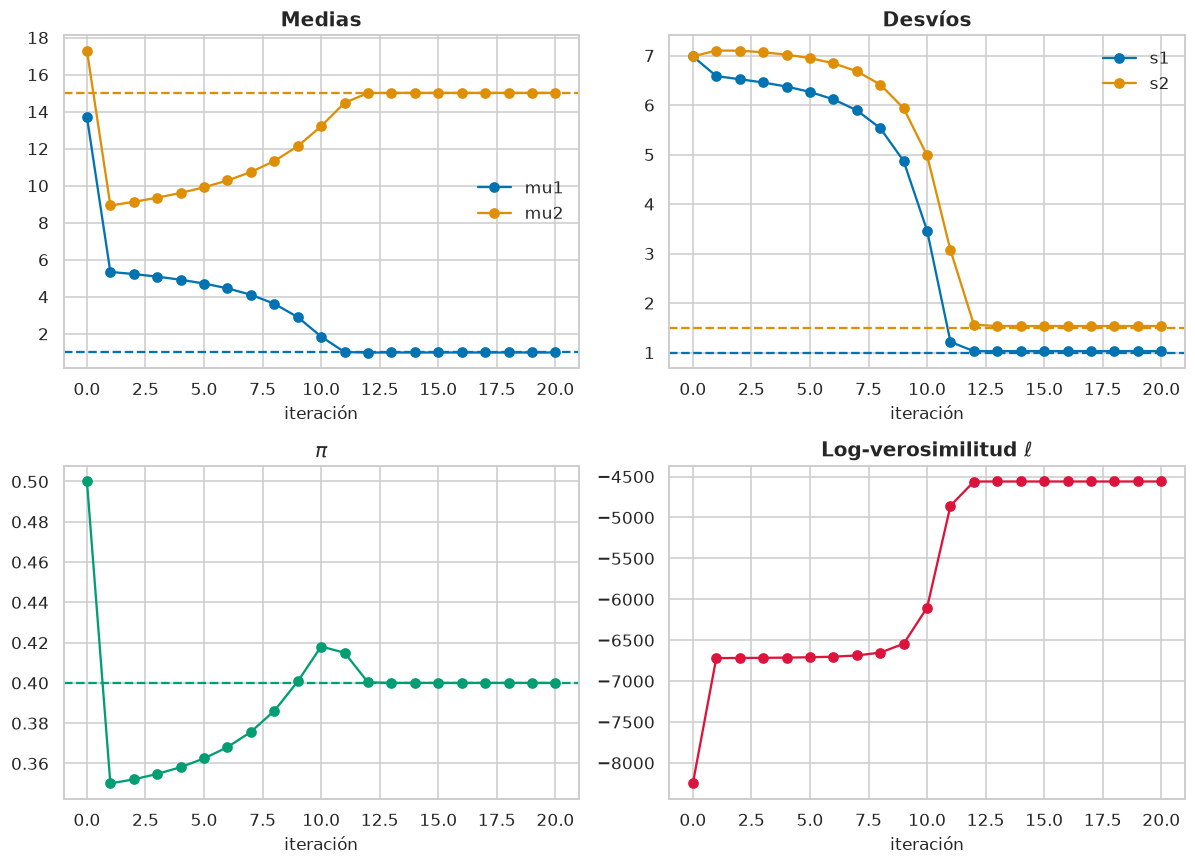

In [9]:
# Celda 23 de la clase: trayectoria de cada parámetro contra su valor verdadero (línea punteada).
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
it = hist.index
for col, verdad, c in [("mu1", mu_1, colores[0]), ("mu2", mu_2, colores[1])]:
    axs[0, 0].plot(it, hist[col], "o-", color=c, label=col); axs[0, 0].axhline(verdad, ls="--", color=c)
for col, verdad, c in [("s1", sigma_1, colores[0]), ("s2", sigma_2, colores[1])]:
    axs[0, 1].plot(it, hist[col], "o-", color=c, label=col); axs[0, 1].axhline(verdad, ls="--", color=c)
axs[1, 0].plot(it, hist["pi"], "o-", color=colores[2]); axs[1, 0].axhline(n_2 / N, ls="--", color=colores[2])
axs[1, 1].plot(it, hist["ell"], "o-", color="crimson")
for ax, t in zip(axs.ravel(), ["Medias", "Desvíos", r"$\pi$", r"Log-verosimilitud $\ell$"]):
    ax.set_title(t); ax.set_xlabel("iteración")
axs[0, 0].legend(); axs[0, 1].legend()
plt.tight_layout(); plt.show()

Lo mismo en gráfico: cada parámetro arrastra una meseta y después se pega a su línea punteada (el valor verdadero) alrededor de la iteración 12. La $\ell$ (abajo a la derecha) sube en escalones: un salto en la iteración 1, casi plana hasta la 8 y un despegue entre la 9 y la 12. La curva de $\ell$ es **monótona**: nunca baja. Si en algún código tuyo de EM la $\ell$ baja, tenés un bug, casi siempre en el orden del M-step o en una responsabilidad mal normalizada.

Que $\hat\pi$ no caiga **exactamente** en $0{,}4$ no es un error: la línea punteada es $800/2000$, y EM estima con una muestra finita.

Ahora la celda 24 de la clase. Allá era un gráfico interactivo de plotly con un deslizador por iteración. Acá va en paneles fijos, para que se vea sin instalar nada: las responsabilidades de cada dato en algunas iteraciones y la frontera donde $\gamma = 1/2$.

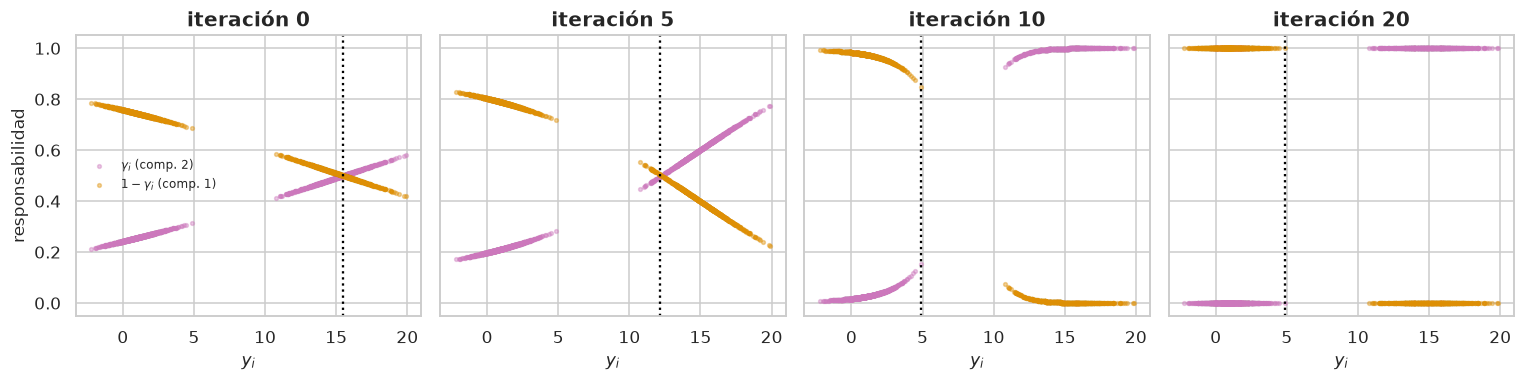

In [10]:
# Celdas 24 y 29: γ_i contra y_i en algunas iteraciones; la frontera es donde γ cruza 1/2.
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
orden = np.argsort(samples)
for ax, k in zip(axs, [0, 5, 10, 20]):
    h = hist.loc[k]
    gk = responsabilidad(samples, h["pi"], h["mu1"], h["s1"], h["mu2"], h["s2"])
    ax.scatter(samples, gk, s=6, alpha=0.4, color=colores[4], label=r"$\gamma_i$ (comp. 2)")
    ax.scatter(samples, 1 - gk, s=6, alpha=0.4, color=colores[1], label=r"$1-\gamma_i$ (comp. 1)")
    cruces = samples[orden][np.where(np.diff(np.sign(gk[orden] - 0.5)))[0]]
    for b in cruces:
        ax.axvline(b, ls=":", color="black")
    ax.set_title(f"iteración {k}"); ax.set_xlabel("$y_i$")
axs[0].set_ylabel("responsabilidad"); axs[0].legend(loc="center left", fontsize=8)
plt.tight_layout(); plt.show()

Qué mirar:

- **Iteración 0:** las dos componentes están en dos datos de la montaña de 15, con $\sigma \approx 7$. Las responsabilidades son una rampa suave: ningún dato está "decidido".
- **Iteración 5 (la meseta):** sigue siendo rampa. La frontera (línea punteada, donde $\gamma = 1/2$) se corrió de 15 a cerca de 12, pero todavía cae **adentro** de la montaña derecha: la mitad de esa montaña se la sigue quedando la componente 1.
- **Iteración 10 (el despegue):** la rampa se vuelve escalón en el hueco entre las montañas.
- **Iteración 20:** es la celda 29 de la clase. Casi todos los datos tienen $\gamma_i \approx 0$ o $\approx 1$, porque las montañas no se pisan. La asignación suave terminó pareciéndose a una dura. Con montañas superpuestas (§2, celda 8) no pasaría: quedaría una franja de datos con $\gamma$ intermedio.

Las etiquetas de la leyenda de la celda 24 de la clase están cruzadas: dibuja $1 - \gamma$ con el nombre *responsabilities* y $\gamma$ con el nombre *1 - responsabilities*. No cambia nada del algoritmo; acá van con el nombre correcto.

Por último, la celda 25: el ajuste final sobre el histograma.

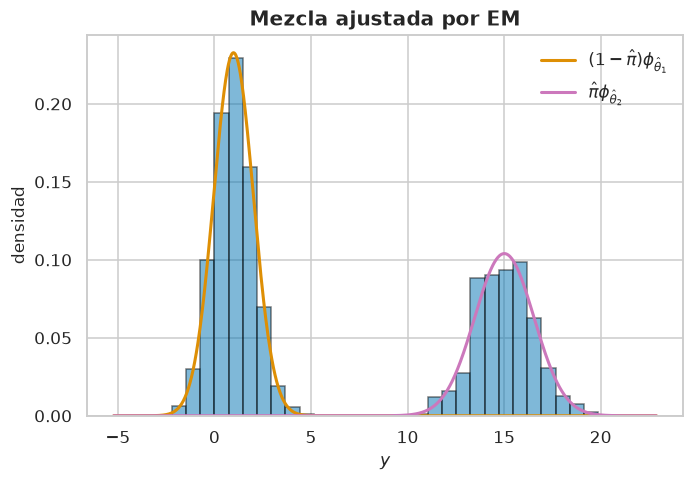

In [11]:
# Celda 25: cada componente ponderada sobre el histograma. Con density=True no hace falta el
# factor N·(ancho de barra) que usa la clase para pasar de densidad a cuentas.
h = hist.iloc[-1]
xx = np.linspace(samples.min() - 3, samples.max() + 3, 1000)
fig, ax = plt.subplots()
ax.hist(samples, bins=30, density=True, alpha=0.5, color=colores[0], edgecolor="black")
ax.plot(xx, (1 - h["pi"]) * norm.pdf(xx, h["mu1"], h["s1"]), color=colores[1], lw=2, label=r"$(1-\hat\pi)\phi_{\hat\theta_1}$")
ax.plot(xx, h["pi"] * norm.pdf(xx, h["mu2"], h["s2"]), color=colores[4], lw=2, label=r"$\hat\pi\phi_{\hat\theta_2}$")
ax.set_xlabel("$y$"); ax.set_ylabel("densidad"); ax.set_title("Mezcla ajustada por EM")
ax.legend(); plt.show()

Cada curva tapa su montaña. En la celda 25 de la clase el histograma está en **cuentas** (sin `density=True`). Para que una densidad se vea a la misma escala hay que multiplicarla por $N$ por el ancho de barra: `len(samples) * (max - min) / 15`. Eso es ese factor raro que multiplica a `pdf_1` y `pdf_2`. Acá normalizamos el histograma y nos lo ahorramos.

##### 🏭 Así se hace en la industria

`sklearn.mixture.GaussianMixture` hace exactamente este EM (con varias inicializaciones si le pedís `n_init`, y un pequeño término `reg_covar` sumado a las varianzas para que no se degeneren).

In [12]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=2, n_init=5, random_state=0).fit(samples.reshape(-1, 1))
orden_k = np.argsort(gm.means_.ravel())          # ordenamos por media para comparar sin label switching
print("medias:", gm.means_.ravel()[orden_k].round(3))
print("desvíos:", np.sqrt(gm.covariances_.ravel()[orden_k]).round(3))
print("pesos:", gm.weights_[orden_k].round(3))
print("ℓ total sklearn vs. a mano:", round(gm.score(samples.reshape(-1, 1)) * N, 1), round(hist["ell"].iloc[-1], 1))

medias: [ 0.989 15.01 ]
desvíos: [1.028 1.535]
pesos: [0.6 0.4]
ℓ total sklearn vs. a mano: -4560.3 -4560.3


Mismos números que el EM a mano. `gm.score` devuelve la log-verosimilitud **promedio** por dato; multiplicada por $N$ es la $\ell$ total y coincide con la de nuestro loop. `gm.predict_proba(X)` te da la matriz de responsabilidades y `gm.predict(X)` el cluster de mayor responsabilidad.

### ❓ La pregunta que quedó abierta

La celda 21 dice *"Buena forma de inicializar"*, pero no dice qué pasa con una **mala**. Si las dos medias arrancan en la misma montaña, EM suele arreglarse igual cuando las montañas están tan separadas como acá. Con montañas pegadas puede quedarse en un máximo local con una componente ancha que cubre todo y otra chica, o puede degenerar (una $\hat\sigma \to 0$ sobre un punto). Por eso `n_init` existe: se corre varias veces y se queda la de mayor $\ell$.

### ⚠️ Confusión típica

Creer que EM encuentra el máximo global. Encuentra un punto donde $\ell$ dejó de subir. Que $\ell$ no baje garantiza que no empeora, no que llegue a lo mejor.

Otra: actualizar los parámetros **uno por uno** con responsabilidades recalculadas en el medio. EM calcula todos los $\gamma_i$ una vez (E-step) y con esos mismos $\gamma_i$ actualiza **todos** los parámetros (M-step). En el código de la celda 21 fijate que `responsabilities` se calcula una vez por vuelta.

Y la tercera: comparar los parámetros de EM con los verdaderos sin mirar el *label switching*. Si te da $\hat\mu_1 \approx 15$ y $\hat\mu_2 \approx 1$, no está mal: está con los nombres cambiados.

## 8. $K$ componentes y el caso multivariado

📓 celdas 26–28 · 📕 ESL §8.5, §14.3 · 📘 Bishop §9.2–9.2.2

### La idea en criollo

Nada de lo anterior dependía de que hubiera **dos** componentes ni de que los datos fueran **escalares**. Con $K$ montañas, la responsabilidad de cada una es su peso en ese punto dividido la suma de los pesos de todas. Con datos en $\mathbb{R}^D$, cada montaña es una gaussiana multivariada con su vector de medias y su matriz de covarianza.

El resultado: el M-step queda con la misma forma, "promedio ponderado por responsabilidades", para cada pieza. Las medias son promedios ponderados de los vectores. Las covarianzas, promedios ponderados de los productos externos $(x - \mu)(x - \mu)^T$. Y los pesos, la fracción $N_k/N$ de "datos efectivos" de cada componente. Esa última sale por Lagrange, porque los pesos tienen que sumar 1. Una vez ajustado, el cluster de cada dato es la componente con mayor responsabilidad.

> **Analogía y dónde se rompe.** Pensalo como un mapa de relieve con $K$ cerros: cada dato le "pertenece" más al cerro cuya ladera ponderada es más alta en ese punto. Se rompe en que en un mapa los cerros son círculos más o menos redondos. Acá cada uno puede ser una elipse estirada y girada (eso lo controla $\Sigma_k$), y dos cerros pueden estar uno adentro del otro, con distinto ancho.

### Formalizándolo

**Movidas:** M10 (verosimilitud completa), M1 (medias y covarianzas), M8 (pesos con $\sum_k\pi_k = 1$).

**El modelo (celda 26, a la Bishop).** La densidad es

$$p(x) = \sum_{k=1}^K\pi_k\,\mathcal N(x \mid \mu_k, \sigma_k^2), \qquad \pi_k \ge 0, \quad \sum_{k=1}^K\pi_k = 1.$$

La restricción deja $K - 1$ pesos libres: el último queda determinado por los demás. Con $K = 2$ es un solo parámetro, el $\pi$ de antes. La latente es $\mathbf z \in \{0,1\}^K$ *one-hot* (un único 1 en la posición de la componente) con $p(z_k = 1) = \pi_k$ y $p(x \mid z_k = 1) = \mathcal N(x \mid \mu_k, \sigma_k^2)$. Con $K = 2$, $z_2 = \Delta$ y $z_1 = 1 - \Delta$: la tabla de la §0.

**Responsabilidades (celda 27).** La misma regla de Bayes de la §6, normalizando sobre las $K$:

$$\gamma_{ik} = P(z_{ik} = 1 \mid x_i) = \frac{\pi_k\,\mathcal N(x_i \mid \mu_k, \sigma_k^2)}{\sum_{j=1}^K\pi_j\,\mathcal N(x_i \mid \mu_j, \sigma_j^2)}.$$

Para cada dato, $\sum_k\gamma_{ik} = 1$. Con dos componentes, "una es el complemento de la otra" (celda 27) es este mismo hecho.

**El caso multivariado (celda 28).** Para $x \in \mathbb{R}^D$:

$$\mathcal N(x \mid \mu_k, \Sigma_k) = \frac{1}{(2\pi)^{D/2}|\Sigma_k|^{1/2}}\exp\!\Big(-\tfrac12(x - \mu_k)^T\Sigma_k^{-1}(x - \mu_k)\Big).$$

$\mu_k \in \mathbb{R}^D$ es el centro de la elipse. $\Sigma_k$ ($D \times D$, simétrica y definida positiva) da su forma y orientación. $|\Sigma_k|$ es su determinante. El exponente es la distancia de Mahalanobis al cuadrado, la misma de LDA/QDA en la clase 6.

**El "y así…" de la celda 28: el M-step general.** La clase lo deja ahí. Lo completamos. Definimos $N_k = \sum_{i=1}^N\gamma_{ik}$, la cantidad **efectiva** de datos de la componente $k$ (con $\gamma$ duras, sería contar).

Con la misma linealidad de la §7, $Q$ es la log-verosimilitud completa con $z_{ik}$ reemplazado por $\gamma_{ik}$ (M10):

$$Q = \sum_{i=1}^N\sum_{k=1}^K\gamma_{ik}\big[\log\pi_k + \log\mathcal N(x_i \mid \mu_k, \Sigma_k)\big].$$

Se separa en un pedazo por componente para $(\mu_k, \Sigma_k)$ y un pedazo $\sum_k N_k\log\pi_k$ para los pesos.

*Medias (M1).* $\log\mathcal N(x_i \mid \mu_k, \Sigma_k) = \text{cte} - \frac12(x_i - \mu_k)^T\Sigma_k^{-1}(x_i - \mu_k)$, donde la constante no depende de $\mu_k$. Con la regla $\frac{\partial}{\partial a}(a^T A a) = 2Aa$ para $A$ simétrica (la de la ecuación normal de la clase 2):

$$\frac{\partial Q}{\partial\mu_k} = \sum_i\gamma_{ik}\,\Sigma_k^{-1}(x_i - \mu_k) = 0.$$

Multiplicamos a izquierda por $\Sigma_k$ (que es invertible) y despejamos:

$$\mu_k = \frac{1}{N_k}\sum_{i=1}^N\gamma_{ik}\,x_i.$$

*Covarianzas.* El mismo procedimiento sobre $\Sigma_k$ (requiere derivar $\log|\Sigma|$ y una forma cuadrática respecto de una matriz; la cuenta está en Bishop §9.2.2 y no la vas a necesitar) da

$$\Sigma_k = \frac{1}{N_k}\sum_{i=1}^N\gamma_{ik}\,(x_i - \mu_k)(x_i - \mu_k)^T.$$

Chequeo: con $D = 1$, $(x_i - \mu_k)(x_i - \mu_k)^T = (x_i - \mu_k)^2$ y es la $\hat\sigma^2$ de la celda 20.

*Pesos (M8).* Maximizamos $\sum_k N_k\log\pi_k$ sujeto a $\sum_k\pi_k = 1$. No se puede derivar e igualar a 0 sin más: sin la restricción, cada $\log\pi_k$ crece con $\pi_k$ y el "óptimo" sería $\pi_k \to \infty$. Lagrange:

$$\mathcal L = \sum_k N_k\log\pi_k + \lambda\Big(1 - \sum_k\pi_k\Big), \qquad \frac{\partial\mathcal L}{\partial\pi_k} = \frac{N_k}{\pi_k} - \lambda = 0 \;\Rightarrow\; \pi_k = \frac{N_k}{\lambda}.$$

Sumamos en $k$ y usamos la restricción: $1 = \sum_k\pi_k = \frac{1}{\lambda}\sum_k N_k = \frac{N}{\lambda}$, porque $\sum_k N_k = \sum_i\sum_k\gamma_{ik} = \sum_i 1 = N$. Entonces $\lambda = N$ y

$$\pi_k = \frac{N_k}{N}.$$

Con $K = 2$, $\pi_2 = \frac1N\sum_i\gamma_i$: la fórmula de la celda 20. Los $\pi_k$ salen $\ge 0$ solos. (Es el mismo M8 de PCA: allá la restricción era $\|v\| = 1$, acá es $\sum_k\pi_k = 1$.)

**Del ajuste al clustering.** Una vez que EM convergió, cada dato va al cluster $\hat k_i = \operatorname{argmax}_k\gamma_{ik}$. Las $\gamma_{ik}$ te dicen además cuán seguro es ese cluster.

### ¿Por qué nos importa?

Porque es el clustering de verdad: en dimensión alta no ves montañas, y este algoritmo las encuentra igual. Y porque te da el puente con lo que ya sabés:

- **QDA** (clase 6) es este mismo modelo con las etiquetas a la vista: un M-step con $\gamma_{ik} \in \{0, 1\}$, sin iterar.
- **K-means** es el límite duro: todas las covarianzas iguales a $\sigma^2\mathbf I$ con $\sigma \to 0$. Las responsabilidades se vuelven 0 o 1 (gana la media más cercana) y el M-step se reduce a promediar. Lo desarrolla Bishop §9.3; ESL lo trata en §14.3.

### En código

Tres componentes en $\mathbb{R}^2$: EM a mano con las fórmulas de arriba, y después la comparación con `sklearn`.

In [13]:
rng = np.random.default_rng(1)
medias_v = [np.array([0, 0]), np.array([4, 4]), np.array([0, 5])]
covs_v = [np.array([[1, 0.6], [0.6, 1]]), np.array([[1, -0.4], [-0.4, 0.5]]), np.eye(2) * 0.4]
X = np.vstack([rng.multivariate_normal(m, S, n) for m, S, n in zip(medias_v, covs_v, [300, 200, 150])])
Nx, K = len(X), 3

mu = X[rng.choice(Nx, K, replace=False)]           # arranque: K datos al azar
Sig = np.array([np.cov(X.T)] * K); pis = np.full(K, 1 / K)
for _ in range(100):
    dens = np.column_stack([pis[k] * multivariate_normal.pdf(X, mu[k], Sig[k]) for k in range(K)])
    gam_k = dens / dens.sum(axis=1, keepdims=True)  # E-step: γ_ik, cada fila suma 1
    Nk = gam_k.sum(axis=0)                          # M-step
    mu = (gam_k.T @ X) / Nk[:, None]
    Sig = np.array([(gam_k[:, k, None] * (X - mu[k])).T @ (X - mu[k]) / Nk[k] for k in range(K)])
    pis = Nk / Nx
print("π_k:", pis.round(3), "(verdaderos: 0.462, 0.308, 0.231)")
print("μ_k:\n", mu.round(2))

π_k: [0.235 0.306 0.459] (verdaderos: 0.462, 0.308, 0.231)
μ_k:
 [[0.1  4.93]
 [4.12 3.91]
 [0.07 0.07]]


Las tres medias y los tres pesos salen cerca de los verdaderos (en algún orden: *label switching* otra vez). Cada línea del loop es una fórmula de la sección. `dens / dens.sum(...)` es la celda 27. `gam_k.T @ X / Nk` son las $K$ medias ponderadas de una vez. El producto `(γ·(X−μ))ᵀ(X−μ)` es $\sum_i\gamma_{ik}(x_i - \mu_k)(x_i - \mu_k)^T$, y `Nk / Nx` es el resultado de Lagrange.

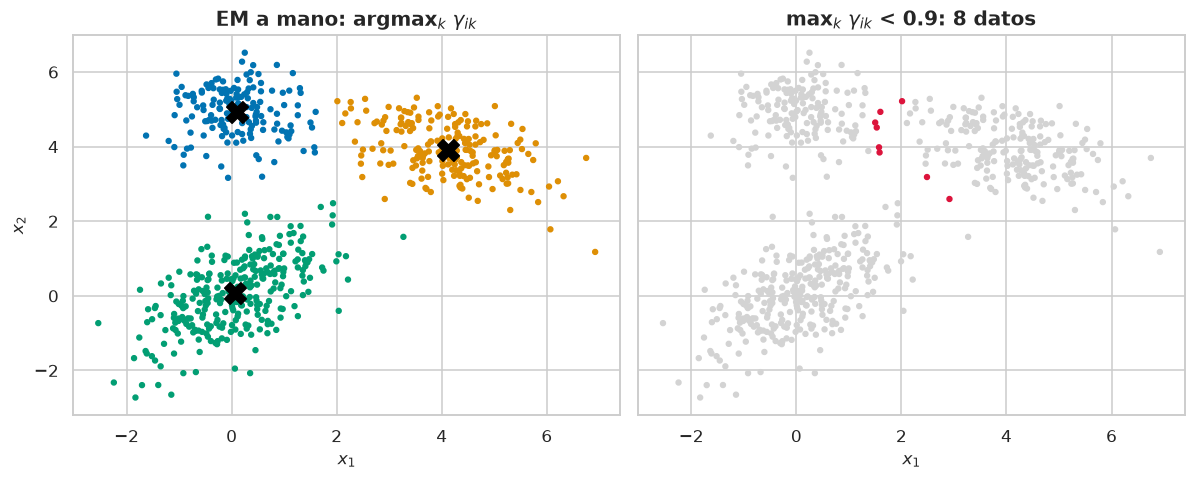

pesos sklearn (ordenados): [0.235 0.305 0.459]  a mano: [0.235 0.306 0.459]


In [14]:
# Clusters = argmax de las responsabilidades; y la misma cuenta con sklearn.
cluster = gam_k.argmax(axis=1)
gm2 = GaussianMixture(n_components=3, random_state=0).fit(X)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
axs[0].scatter(X[:, 0], X[:, 1], c=[colores[c] for c in cluster], s=10)
axs[0].scatter(mu[:, 0], mu[:, 1], marker="X", s=200, color="black")
axs[0].set_title("EM a mano: argmax$_k\\ \\gamma_{ik}$")
incierto = gam_k.max(axis=1) < 0.9                      # datos sin un dueño claro
axs[1].scatter(X[:, 0], X[:, 1], c=np.where(incierto, "crimson", "lightgray"), s=10)
axs[1].set_title(f"max$_k\\ \\gamma_{{ik}}$ < 0.9: {incierto.sum()} datos")
for ax in axs: ax.set_xlabel("$x_1$")
axs[0].set_ylabel("$x_2$"); plt.tight_layout(); plt.show()
print("pesos sklearn (ordenados):", np.sort(gm2.weights_).round(3), " a mano:", np.sort(pis).round(3))

A la izquierda, cada dato pintado con su cluster y las medias estimadas marcadas con una cruz. A la derecha, en rojo, los datos **sin dueño claro** (ninguna componente tiene más de 0,9 de responsabilidad). Están en las zonas donde dos elipses se tocan. Esa información la da EM y no la da un clustering duro como K-means. Los pesos de `sklearn` coinciden con los del loop a mano.

### ⚠️ Confusión típica

Contar mal los parámetros libres. Con $K$ componentes en $\mathbb{R}^D$ hay $K - 1$ pesos (no $K$), $KD$ medias y $K\frac{D(D+1)}{2}$ entradas de covarianza (son simétricas). Ese número crece rápido con $D$, y por eso en dimensión alta se restringen las $\Sigma_k$ (diagonales, o una sola compartida).

Otra: maximizar los $\pi_k$ derivando $\sum_k N_k\log\pi_k$ e igualando a 0 sin la restricción. La derivada $N_k/\pi_k$ nunca es 0. Sin Lagrange (M8) no hay óptimo.

## 🧮 Para derivar en frío

Hoja en blanco, sin mirar la notebook. Si te trabás, en este orden: el nombre de la movida (`tutor/movidas.md`), `/tutor duda`, y recién después la sección que indica cada una (una línea, y la cerrás). Si llegás a la notebook, va al diario.

### 1. Por qué la máxima verosimilitud directa no tiene forma cerrada

- **Consigna:** para la mezcla $g_Y(y) = (1-\pi)\phi_{\theta_1}(y) + \pi\phi_{\theta_2}(y)$ con datos $y_1, \dots, y_N$ independientes, escribí la log-verosimilitud $\ell(\theta)$. Derivala respecto de $\mu_2$, igualá a 0 y mostrá que la condición es $\mu_2 = \sum_i\gamma_i y_i / \sum_i\gamma_i$ con $\gamma_i = \frac{\pi\phi_{\theta_2}(y_i)}{g_Y(y_i)}$. Explicá por qué eso **no** es una forma cerrada y qué algoritmo sugiere.
- **Movidas:** M10, M1.
- **Tiempo objetivo:** 8 min.
- **Si te trabás:** §4 (Pasos 1 a 4).

### 2. Los estimadores con las $\Delta_i$ conocidas

- **Consigna:** con $p(y_i, \Delta_i) = [(1-\pi)\phi_{\theta_1}(y_i)]^{1-\Delta_i}[\pi\phi_{\theta_2}(y_i)]^{\Delta_i}$, escribí la log-verosimilitud completa $\ell_0(\theta; \mathbf Z, \boldsymbol\Delta)$, mostrá que se separa en tres sumas y derivá $\hat\mu_1$, $\hat\sigma_1^2$ y $\hat\pi$. Decí por qué el M-step de EM se obtiene cambiando $\Delta_i$ por $\gamma_i$ (una línea: ¿qué propiedad de $\ell_0$ lo permite?).
- **Movidas:** M10, M1.
- **Tiempo objetivo:** 10 min.
- **Si te trabás:** §5 ("Los estimadores") y §7 ("¿Por qué está bien enchufar $\hat\gamma_i$…?").

### 3. La responsabilidad por Bayes

- **Consigna:** mostrá que $E[\Delta_i \mid \theta, \mathbf Z] = P(\Delta_i = 1 \mid y_i)$ y calculala con la regla de Bayes. Generalizá a $K$ componentes ($\gamma_{ik}$) y decí dónde queda la frontera $\gamma = 1/2$ cuando $\pi = 1/2$ y $\sigma_1 = \sigma_2$.
- **Movidas:** ninguna del catálogo (regla de Bayes; es el posterior de LDA/QDA de la clase 6).
- **Tiempo objetivo:** 6 min.
- **Si te trabás:** §6 (Formalizándolo) y §8 ("Responsabilidades").

### 4. Los pesos $\pi_k$ con $K$ componentes

- **Consigna:** en el M-step con $K$ componentes, maximizá $\sum_{k=1}^K N_k\log\pi_k$ sujeto a $\sum_k\pi_k = 1$, con $N_k = \sum_i\gamma_{ik}$. Mostrá que $\pi_k = N_k/N$ (necesitás probar que $\sum_k N_k = N$). Chequeá que con $K = 2$ recuperás $\hat\pi = \frac1N\sum_i\gamma_i$.
- **Movidas:** M8, M1.
- **Tiempo objetivo:** 6 min.
- **Si te trabás:** §8 ("Pesos").

## 🧵 El hilo conductor

Toda la materia hasta la clase 7 fue supervisada: había una $Y$, una pérdida y un error que la validación cruzada podía medir. Esta clase saca la $Y$ y se queda con $P(X)$. Lo primero que hace es convertir una pregunta vaga ("encontrá estructura") en una pregunta de estimación. Los clusters son las modas de $P(X)$, $P(X)$ se modela como una mezcla de gaussianas, y encontrar los clusters es estimar los parámetros de la mezcla por máxima verosimilitud, como en las clases 3 (OLS) y 6 (logística).

La diferencia con aquellas clases está en un detalle de álgebra con consecuencias enormes. El log de una **suma** no se separa, así que no hay forma cerrada. La salida es inventar la variable que falta, $\Delta_i$. Con ella la verosimilitud completa se separa y los estimadores son promedios por grupo, igual que en LDA/QDA cuando tenías las etiquetas. Sin ella, la reemplazás por su esperanza dada la información que tenés: la responsabilidad $\gamma_i$, que es el mismo posterior de Bayes de la clase 6. EM alterna las dos cosas, y cada vuelta sube la verosimilitud hasta un máximo local. Si derivás la verosimilitud de la mezcla directamente, llegás al mismo lugar: la condición de óptimo es un punto fijo que EM itera.

La otra herramienta de la clase, la reducción de dimensionalidad, ya la tenés desarrollada en el material de PCA (`books/explained/cap14_5_pca_componentes_principales.ipynb`), que vuelve a usar la SVD de la clase 3. Desde acá, el capítulo 14 de ESL sigue con K-means (el límite duro de esta clase), clustering jerárquico y métodos no lineales. Y EM reaparece cada vez que un modelo tiene algo no observado: datos faltantes, modelos de Markov ocultos, mezclas de cualquier familia.

## ✅ Autoevaluación

**1.** ¿Por qué en aprendizaje supervisado no hace falta modelar $P(X)$ y en no supervisado sí?

<details><summary>Respuesta</summary>

Porque $P(X, Y) = P(Y \mid X)\,P(X)$ y para predecir $Y$ dado un $x$ alcanza con el primer factor (o un resumen suyo, como $E(Y \mid X = x)$): el $x$ te lo dan. En no supervisado no hay $Y$. Lo único que existe es $X$, así que cualquier pregunta ("¿cuántos grupos?", "¿de qué grupo es este dato?") es una pregunta sobre $P(X)$.

</details>

**2.** Un dato tiene $\gamma_i = 0{,}5$. ¿Qué significa? ¿Y $\pi = 0{,}5$?

<details><summary>Respuesta</summary>

$\gamma_i = 0{,}5$: **ese** dato, después de ver su valor, tiene la misma probabilidad de venir de cada componente. Está en la frontera, donde $\pi\phi_{\theta_2}(y_i) = (1-\pi)\phi_{\theta_1}(y_i)$. $\pi = 0{,}5$ es una afirmación **global**: antes de ver nada, la mitad de los datos vienen de cada componente. Puede haber $\pi = 0{,}5$ y que casi todos los $\gamma_i$ sean 0 o 1 (montañas separadas, como en la clase).

</details>

**3.** (Cuenta) Mezcla con $\pi = 0{,}2$, $\mu_1 = 0$, $\mu_2 = 2$, $\sigma_1 = \sigma_2 = 1$. Calculá $\gamma$ en $y = 1$.

<details><summary>Respuesta</summary>

En $y = 1$ las dos gaussianas están a distancia 1 de su media, así que $\phi_{\theta_1}(1) = \phi_{\theta_2}(1)$ (llamalo $c$). Entonces $\gamma = \frac{0{,}2c}{0{,}8c + 0{,}2c} = 0{,}2$. En el punto medio, con varianzas iguales, las verosimilitudes se cancelan y la responsabilidad es el prior. La frontera $\gamma = 1/2$ no está en $y = 1$: se corre hacia la componente que pesa menos (hacia $\mu_2$), porque hace falta más evidencia para asignarle un dato.

</details>

**4.** (Cuenta) Tras un E-step con $N = 4$ datos, $y = (0, 1, 9, 10)$, tenés $\gamma = (0, 0{,}2, 0{,}8, 1)$. Hacé el M-step para $\mu_2$ y $\pi$.

<details><summary>Respuesta</summary>

$\sum_i\gamma_i = 0 + 0{,}2 + 0{,}8 + 1 = 2$, así que $\hat\pi = 2/4 = 0{,}5$. $\sum_i\gamma_i y_i = 0 + 0{,}2 + 7{,}2 + 10 = 17{,}4$, así que $\hat\mu_2 = 17{,}4/2 = 8{,}7$. Fijate que $\hat\mu_2$ no es el promedio de $\{9, 10\}$ (9,5): el dato en 1 aporta un poco (0,2 de dato) y el de 9 cuenta solo 0,8. Por simetría, $\hat\mu_1 = \frac{1\cdot0 + 0{,}8\cdot1 + 0{,}2\cdot9 + 0\cdot10}{2} = 1{,}3$.

</details>

**5.** ¿Por qué no se puede usar la log-verosimilitud completa $\ell_0$ directamente para estimar? ¿Y por qué sí se puede usar su esperanza?

<details><summary>Respuesta</summary>

$\ell_0$ depende de las $\Delta_i$, que no observás: no la podés evaluar. Su esperanza dados los datos y los parámetros actuales sí se puede calcular. Como $\ell_0$ es lineal en cada $\Delta_i$, la esperanza solo cambia cada $\Delta_i$ por $\gamma_i = E[\Delta_i \mid \mathbf Z, \hat\theta]$, que se calcula con Bayes. Eso es el E-step.

</details>

**6.** ¿Qué pasa si inicializás EM con $\hat\mu_1 = \hat\mu_2$ y $\hat\sigma_1 = \hat\sigma_2$?

<details><summary>Respuesta</summary>

Las dos componentes son idénticas, así que para todo dato $\phi_{\hat\theta_1}(y_i) = \phi_{\hat\theta_2}(y_i)$ y $\gamma_i = \hat\pi$ para todos. El M-step da $\hat\mu_1 = \hat\mu_2 = \bar y$ y $\hat\sigma_1^2 = \hat\sigma_2^2$ = la varianza total. Las componentes siguen idénticas y EM no se mueve nunca. Es un punto estacionario de $\ell$ que no es un máximo. Por eso se inicializa con dos datos distintos.

</details>

**7.** ¿Qué pasa si corrés EM con $K = 3$ sobre los datos de la clase, que tienen dos montañas? ¿La $\ell$ final es mayor o menor que con $K = 2$?

<details><summary>Respuesta</summary>

Mayor o igual: el modelo con $K = 3$ incluye al de $K = 2$ (poné un peso en 0), así que su máximo no puede ser peor. En la práctica, una montaña se parte en dos componentes, o aparece una tercera componente chica y ancha. $\ell$ sube con $K$ como el error de entrenamiento baja con la complejidad (clase 7), así que $\ell$ sola no sirve para elegir $K$. Hace falta penalizar (BIC) o validar en datos no vistos.

</details>

**8.** ¿Por qué la máxima verosimilitud de una mezcla de gaussianas no tiene máximo global útil? ¿Cómo lo evita `sklearn` en la práctica?

<details><summary>Respuesta</summary>

Si centrás una componente en un dato ($\mu_k = y_j$) y hacés $\sigma_k \to 0$, el término de $y_j$ tiene densidad $\frac{1}{\sqrt{2\pi}\sigma_k} \to \infty$ mientras los demás siguen finitos porque los cubre otra componente. $\ell \to +\infty$. `GaussianMixture` suma un pequeño `reg_covar` a la diagonal de cada covarianza (no deja que llegue a 0) y corre varias inicializaciones (`n_init`) para quedarse con un máximo local bueno.

</details>

**9.** Explicá en qué se diferencian EM para una mezcla de gaussianas y QDA, si los dos usan $\pi_k$, $\mu_k$, $\Sigma_k$ y el mismo posterior.

<details><summary>Respuesta</summary>

QDA es supervisado: las etiquetas están, así que estima $\pi_k$, $\mu_k$, $\Sigma_k$ con promedios por clase **una vez** (un M-step con $\gamma_{ik} \in \{0,1\}$ conocidos) y usa el posterior solo para clasificar datos nuevos. En la mezcla las etiquetas no están, así que el posterior se usa **durante el entrenamiento** para inventar etiquetas suaves, y hay que iterar porque esas etiquetas dependen de los parámetros.

</details>

## 🎯 Centros para los ejercicios

La clase no trajo ejercicios: el `.ipynb` de ejercicios quedó sin consignas. Para practicar esta clase usá las derivaciones de 🧮 y `/tutor practica no_supervisado`.